# Setup

In [1]:
lapply(c('viridis', 'ggthemes', 'skimr'),
       function(pkg_name) { if(! pkg_name %in% installed.packages()) { install.packages(pkg_name)} } )

library(viridis)    # A nice color scheme for plots.
library(ggthemes)   # Common themes to change the look and feel of plots.
library(scales)     # Graphical scales map data to aesthetics in plots.
library(skimr)      # Better summaries of data.
library(lubridate)  # Date library from the tidyverse.
library(tidyverse)  # Data wrangling packages.
library(bigrquery)  # Data extraction from Google BigQuery
library(data.table )

# Load required libraries
library(dplyr)
library(tidyr)
library(purrr)
library(broom)

install.packages("pROC")
install.packages("pheatmap")

install.packages("effects")
library(effects)


library(pheatmap)

## Plot setup.
theme_set(theme_bw(base_size = 14)) # Default theme for plots.

#' Returns a data frame with a y position and a label, for use annotating ggplot boxplots.
#'
#' @param d A data frame.
#' @return A data frame with column y as max and column label as length.
get_boxplot_fun_data <- function(df) {
  return(data.frame(y = max(df), label = stringr::str_c('N = ', length(df))))
}

# Get the bucket name
my_bucket <- Sys.getenv('WORKSPACE_BUCKET')

[[1]]
NULL

[[2]]
NULL

[[3]]
NULL

Loading required package: viridisLite


Attaching package: ‘scales’


The following object is masked from ‘package:viridis’:

    viridis_pal



Attaching package: ‘lubridate’


The following objects are masked from ‘package:base’:

    date, intersect, setdiff, union


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr   1.1.4     ✔ readr   2.1.5
✔ forcats 1.0.0     ✔ stringr 1.5.1
✔ ggplot2 3.5.2     ✔ tibble  3.2.1
✔ purrr   1.0.4     ✔ tidyr   1.3.1
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ readr::col_factor() masks scales::col_factor()
✖ purrr::discard()    masks scales::discard()
✖ dplyr::filter()     masks stats::filter()
✖ dplyr::lag()        masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors

Attaching package: ‘data.table’


The following objects are masked from ‘package:dplyr’:

    between, first, last


The following object is

In [2]:
name_of_file_in_bucket <- 'adjusted_PRS_scores.csv'

# Copy the file from current workspace to the bucket
system(paste0("gsutil cp ", my_bucket, "/data/", name_of_file_in_bucket, " ."), intern=T)

# Load the file into a dataframe
PRS  <- read_csv(name_of_file_in_bucket) 


character(0)

Rows: 135205 Columns: 10
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (10): person_id, Asthma_adjusted_score, Afib_adjusted_score, BreastC_adj...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


## Load and merge data

In [3]:
# replace 'test.csv' with the name of the file in your google bucket (don't delete the quotation marks)
name_of_file_in_bucket <- 'Case_Control_df.csv'

# Copy the file from current workspace to the bucket
system(paste0("gsutil cp ", my_bucket, "/data/", name_of_file_in_bucket, " ."), intern=T)

# Load the file into a dataframe
Case_Control_df  <- read_csv(name_of_file_in_bucket)



character(0)

Rows: 252272 Columns: 10
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (10): person_id, Asthma, Afib, BreastC, CKD, CHD, HyperC, ProstateC, t2d...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [4]:
# This snippet assumes that you run setup first

# This code copies a file from your Google Bucket into a dataframe

# replace 'test.csv' with the name of the file in your google bucket (don't delete the quotation marks)
name_of_file_in_bucket <- 'SES_cohort.csv'

########################################################################
##
################# DON'T CHANGE FROM HERE ###############################
##
########################################################################

# Get the bucket name
my_bucket <- Sys.getenv('WORKSPACE_BUCKET')

# Copy the file from current workspace to the bucket
system(paste0("gsutil cp ", my_bucket, "/data/", name_of_file_in_bucket, " ."), intern=T)

# Load the file into a dataframe
SES_data  <- read_csv(name_of_file_in_bucket) 

character(0)

Rows: 104657 Columns: 84
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr   (7): SexGender, ancestry_pred, where_born, military, healthcare, disab...
dbl  (66): person_id, race_unknown, age_today, PC_1, PC_2, PC_3, PC_4, PC_5,...
lgl   (8): AIAN, Asian, Black, Mid, Multiple, PI, White, His
date  (3): date_of_birth, min_date, max_date

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [5]:
merged_data<-merge(PRS, Case_Control_df, on="person_id", how="left")
merged_data<-merge(merged_data, SES_data, on="person_id", how="left")

dim(merged_data)
colnames(merged_data)

[1] 104564    102

[1] "person_id"                     "Asthma_adjusted_score"        
  [3] "Afib_adjusted_score"           "BreastC_adjusted_score"       
  [5] "CKD_adjusted_score"            "CHD_adjusted_score"           
  [7] "HyperC_adjusted_score"         "ProstateC_adjusted_score"     
  [9] "t1d_adjusted_score"            "t2d_adjusted_score"           
 [11] "Asthma"                        "Afib"                         
 [13] "BreastC"                       "CKD"                          
 [15] "CHD"                           "HyperC"                       
 [17] "ProstateC"                     "t2d"                          
 [19] "t1d"                           "date_of_birth"                
 [21] "AIAN"                          "Asian"                        
 [23] "Black"                         "Mid"                          
 [25] "Multiple"                      "PI"                           
 [27] "White"                         "His"                          
 [29] "race_unknown"                  "SexGender"                    
 [31] "age_today"                     "ancestry_pred"                
 [33] "PC_1"                          "PC_2"                         
 [35] "PC_3"                          "PC_4"                         
 [37] "PC_5"                          "PC_6"                         
 [39] "PC_7"                          "PC_8"                         
 [41] "PC_9"                          "PC_10"                        
 [43] "PC_11"                         "PC_12"                        
 [45] "PC_13"                         "PC_14"                        
 [47] "PC_15"                         "PC_16"                        
 [49] "where_born"                    "military"                     
 [51] "healthcare"                    "disabled"                     
 [53] "sexual_orientation"            "LGBTQIA"                      
 [55] "min_date"                      "max_date"                     
 [57] "ehr_length"                    "relative_health"              
 [59] "record_depth"                  "visit_frequency"              
 [61] "age"                           "record_depth_winsorized"      
 [63] "visit_frequency_winsorized"    "education"                    
 [65] "employment"                    "income"                       
 [67] "home_own"                      "number_living"                
 [69] "median_adjusted_income"        "number_living_adjusted_income"
 [71] "income_adjusted_both"          "health_literacy"              
 [73] "housing_quality"               "housing_instability"          
 [75] "food_insecurity"               "Walkability"                  
 [77] "loneliness"                    "crime_saftey"                 
 [79] "npd_scale"                     "nsd_scale"                    
 [81] "discrimination"                "health_discrim"               
 [83] "social_cohesion"               "stress"                       
 [85] "social_support"                "spirituality"                 
 [87] "health_coverage"               "health_care_use"              
 [89] "delayed_care"                  "afford_care"                  
 [91] "worried_pay"                   "respect"                      
 [93] "housing_type"                  "per_poverty_threshold"        
 [95] "assisted_income"               "high_school_education"        
 [97] "median_income"                 "no_health_insurance"          
 [99] "poverty"                       "vacant_housing"               
[101] "deprivation_index"             "age2"

In [6]:
merged_data <- merged_data %>%
  mutate(
    SexGenderCis_male = ifelse(SexGender == "Cis_male", 1, 0),
    SexGenderCis_female = ifelse(SexGender == "Cis_female", 1, 0),
    SexGenderSGM = ifelse(SexGender == "SGM", 1, 0)
  )

## Set up lists

In [7]:
diseases<-c("Asthma", "Afib", "BreastC", "CKD", "CHD", "HyperC", "ProstateC", "t2d", "t1d")
domains<-c('per_poverty_threshold', 'education', 'assisted_income', 'high_school_education', 'median_income', 'no_health_insurance',
           'poverty', 'vacant_housing', 'deprivation_index')
PCs<-c("PC_1", "PC_2")         
           
merged_data <- merged_data %>%
  mutate(across(all_of(domains), ~ (. - min(., na.rm = TRUE)) / (max(., na.rm = TRUE) - min(., na.rm = TRUE))))

merged_data$high_school_education <- 1 - merged_data$high_school_education
merged_data$median_income <- 1 - merged_data$median_income
merged_data$education <- 1 - merged_data$education
merged_data$per_poverty_threshold <- 1 - merged_data$per_poverty_threshold


# Remove outliers and rescale

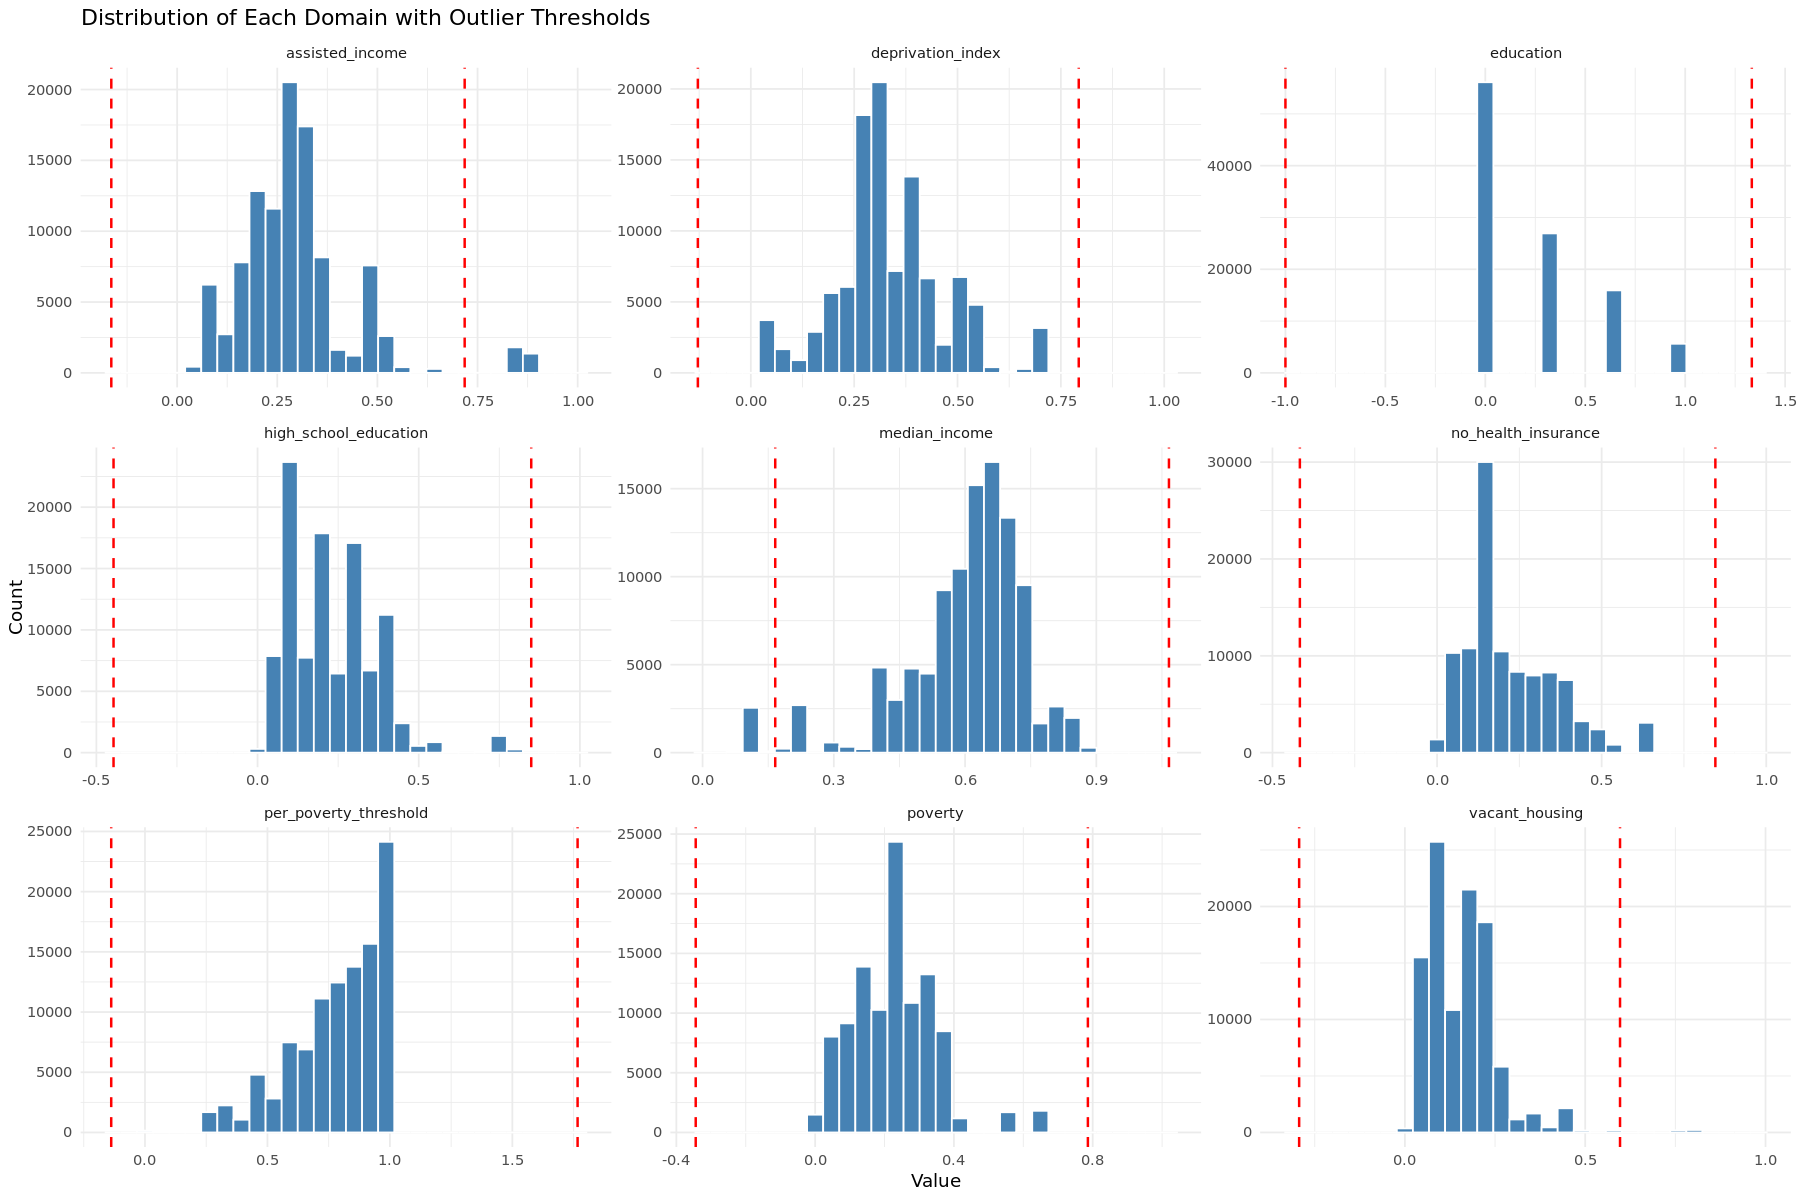

In [8]:
# Pivot to long format
long_data <- merged_data %>%
  pivot_longer(cols = all_of(domains), names_to = "domain", values_to = "value")

# Calculate IQR-based outlier thresholds for each domain
outlier_limits <- long_data %>%
  group_by(domain) %>%
  summarise(
    Q1 = quantile(value, 0.25, na.rm = TRUE),
    Q3 = quantile(value, 0.75, na.rm = TRUE),
    IQR = Q3 - Q1,
    lower = Q1 - 3 * IQR,
    upper = Q3 + 3 * IQR
  )

options(repr.plot.width = 15, repr.plot.height = 10)  # Set width and height

# Plot histograms with outlier lines
ggplot(long_data, aes(x = value)) +
  geom_histogram(bins = 30, fill = "steelblue", color = "white") +
  geom_vline(
    data = outlier_limits,
    aes(xintercept = lower),
    color = "red", linetype = "dashed", linewidth = 0.7
  ) +
  geom_vline(
    data = outlier_limits,
    aes(xintercept = upper),
    color = "red", linetype = "dashed", linewidth = 0.7
  ) +
  facet_wrap(~ domain, scales = "free") +
  theme_minimal() +
  labs(
    x = "Value",
    y = "Count",
    title = "Distribution of Each Domain with Outlier Thresholds"
  )



[1] 104564

[1] 98239

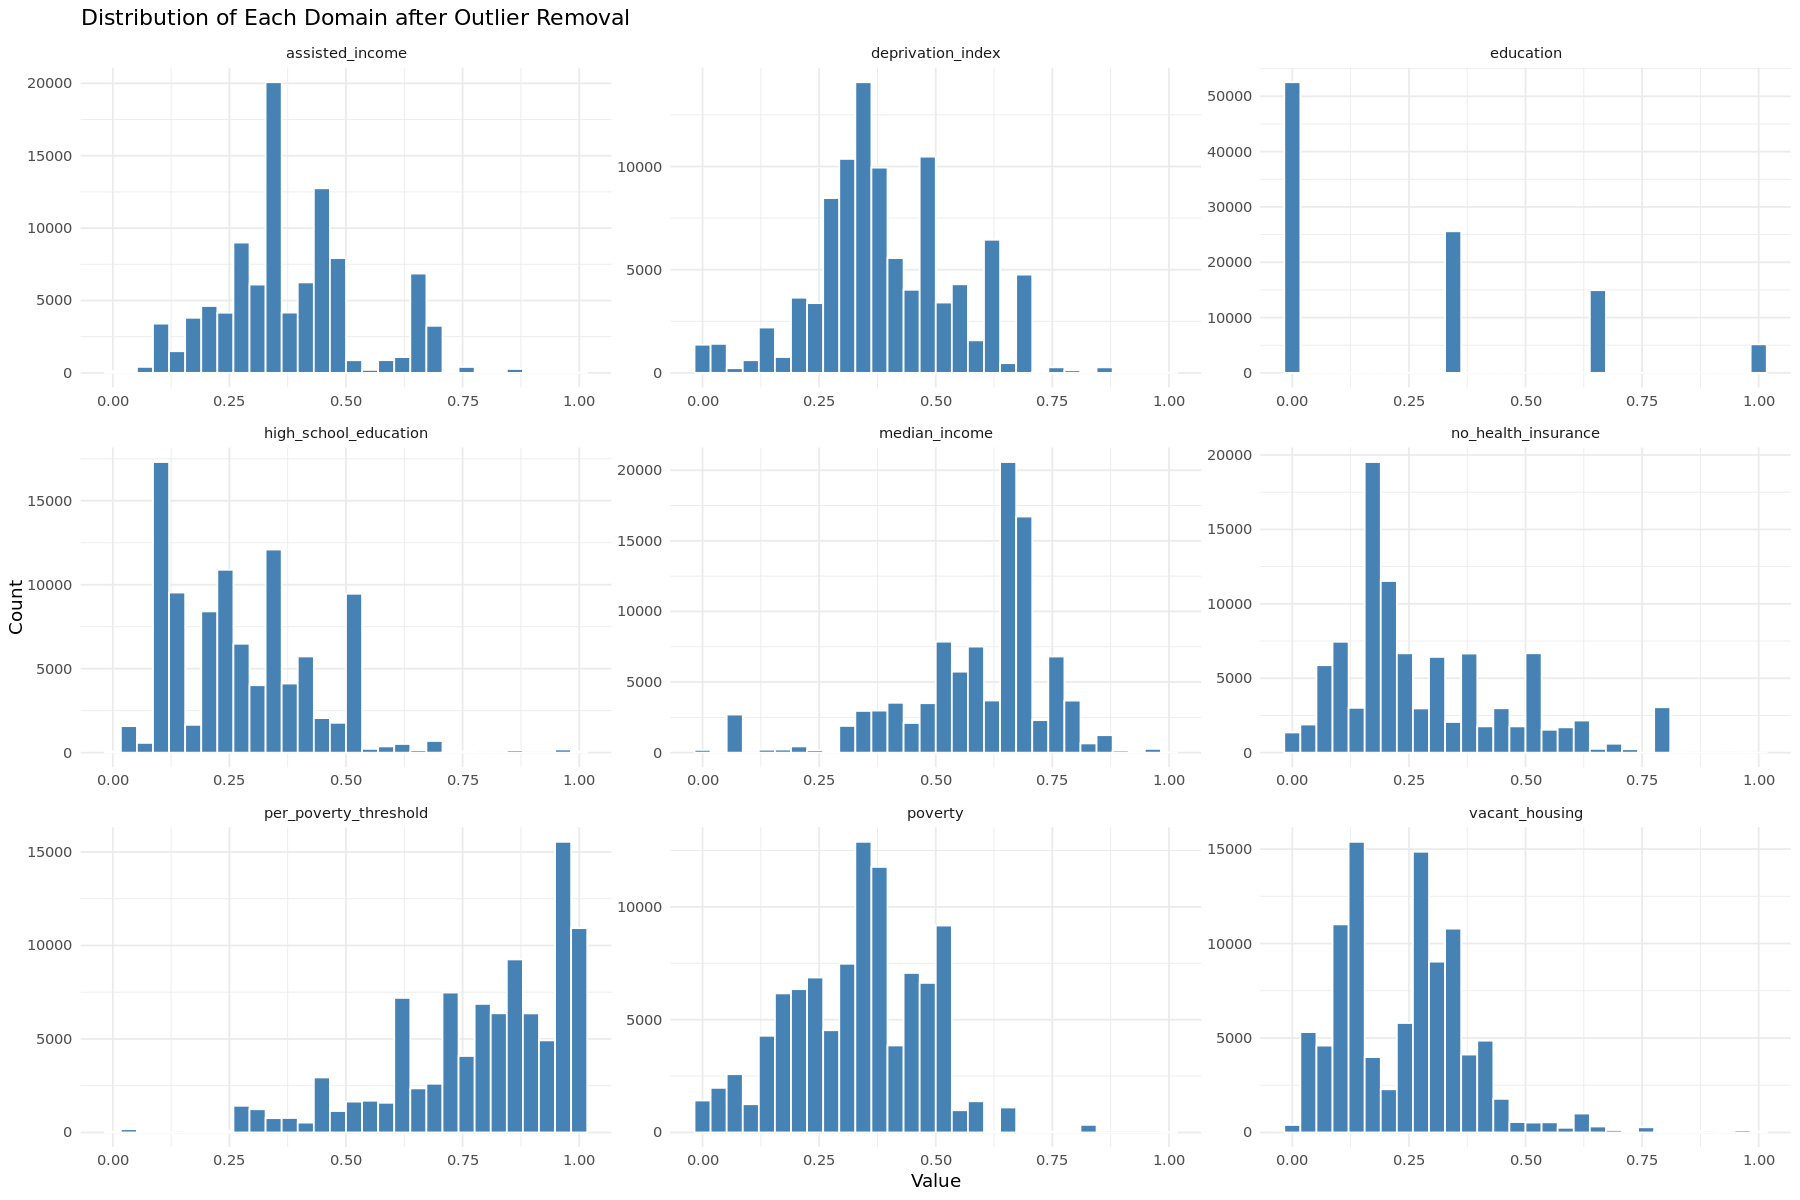

In [9]:
# Step 3: Join limits, remove outliers
# Step 3a: Identify outlier person_ids
outlier_ids <- long_data %>%
  left_join(outlier_limits, by = "domain") %>%
  filter(value < lower | value > upper) %>%
  pull(person_id) %>%
  unique()

# Step 3b: Remove those person_ids from all domains
long_filtered <- long_data %>%
  filter(!person_id %in% outlier_ids)

# Step 4: Normalize (min-max) per domain
normalized_long <- long_filtered %>%
  group_by(domain) %>%
  mutate(scaled_value = (value - min(value, na.rm = TRUE)) / 
                          (max(value, na.rm = TRUE) - min(value, na.rm = TRUE))) %>%
  ungroup()

# Plot histograms with outlier lines
ggplot(normalized_long, aes(x = scaled_value)) +
  geom_histogram(bins = 30, fill = "steelblue", color = "white") +
  facet_wrap(~ domain, scales = "free") +
  theme_minimal() +
  labs(
    x = "Value",
    y = "Count",
    title = "Distribution of Each Domain after Outlier Removal"
  )

# Step 5 (optional): Pivot back to wide format with scaled values
normalized_wide <- normalized_long %>%
  select(person_id, domain, scaled_value) %>%
  pivot_wider(names_from = domain, values_from = scaled_value)

nrow(merged_data)
nrow(normalized_wide)


In [10]:
# Step 1: Drop original domain columns from merged_data
#merged_data_clean <- merged_data %>%
#  select(-all_of(domains))  # `domains` is your vector of domain column names

# Step 2: Join normalized values back in
#merged_data <- merged_data_clean %>%
#  left_join(normalized_wide, by = "person_id")

# Regressions

## Models

In [11]:
library(dplyr)
library(broom)
library(pROC)

# Model labels
models <- c("PRS:PC", "Social:PC", "PRS:Social")

# Function to generate formulas for disease-domain pairs
generate_formulas <- function(disease, domain, model, PC) {
  # Base covariates
  covariates <- c("age", "age2", "record_depth", "visit_frequency")
  
  # All possible sex terms
  sex_terms <- c("SexGenderCis_male", "SexGenderSGM")
  
  # Disease-specific exclusions
  if (disease == "CKD" || disease == "t1d") {
    sex_terms <- setdiff(sex_terms, "SexGenderSGM")
  }
  if (disease == "BreastC") {
    sex_terms <- setdiff(sex_terms, "SexGenderCis_male")
  }
  if (disease == "ProstateC") {
    sex_terms <- setdiff(sex_terms, "SexGenderCis_male")
  }

  # Combine covariates
  base <- paste(c(covariates, sex_terms), collapse = " + ")
  score <- paste0(disease, "_adjusted_score")
  prcomp <- PC
  prspc <- paste0(score, ":", PC)
  socialpc <- paste0(domain, ":", PC)
  prssocial <- paste0(score, ":", domain)

  # Return all 5 models
  list(
    as.formula(paste(disease, "~", paste(c(base, score, prcomp, prspc), collapse = " + "))),
    as.formula(paste(disease, "~", paste(c(base, domain, prcomp, socialpc), collapse = " + "))),
    as.formula(paste(disease, "~", paste(c(base, score, domain, prssocial), collapse = " + ")))

  )
}

Type 'citation("pROC")' for a citation.


Attaching package: ‘pROC’


The following objects are masked from ‘package:stats’:

    cov, smooth, var




## Auc

In [12]:
# Updated function to fit models and extract results
fit_and_extract <- function(formulas, disease, domain, models, data) {
  map2_dfr(formulas, models, ~ {
      
    # Filter data based on disease-specific sex/gender logic
    filtered_data <- data
    
    if (disease %in% c("CKD", "t1d")) {
      filtered_data <- filtered_data %>% filter(SexGenderSGM == 0)
    }
    if (disease == "BreastC") {
      filtered_data <- filtered_data %>% filter(SexGenderCis_male == 0)
    }
    if (disease == "ProstateC") {
      filtered_data <- filtered_data %>% filter(SexGenderCis_female == 0)
    }

    # Remove rows with missing values in any variables used in the formula
    vars_in_model <- all.vars(.x)
    filtered_data <- filtered_data %>% filter(if_all(all_of(vars_in_model), ~ !is.na(.)))

    # Fit the model
    model <- glm(.x, data = filtered_data, family = binomial(link = "logit"))
    
    # Calculate predictions and actual values for AUC
    preds <- predict(model, type = "response")
    actuals <- model$y
    
    # Calculate AUC and 95% CI
    if (length(unique(actuals)) > 1) {
      roc_obj <- roc(actuals, preds, quiet = TRUE)  # ROC object
      auc <- as.numeric(roc_obj$auc)  # AUC value
      auc_ci <- ci.auc(roc_obj)  # AUC confidence interval
    } else {
      auc <- NA
      auc_ci <- c(NA, NA, NA)  # Placeholder for CI
    }
    
    # Model coefficients
    tidy(model) %>%
      mutate(
        Disease = disease,
        Domain = domain,
        Model = .y,
        AUC = auc,
        AUC_CI_Lower = auc_ci[1],
        AUC_CI_Upper = auc_ci[3]
      )
  })
}

# Step 1: Generate combinations of diseases and domains
combinations <- expand_grid(
  disease = unlist(diseases),
  domain = domains,
    PC = PCs
)

# Step 2: Generate formulas and fit models
results <- combinations %>%
  rowwise() %>%
  mutate(
    formulas = list(generate_formulas(disease, domain, model=NULL, PC)),
    model_results = list(fit_and_extract(formulas, disease, domain, models, merged_data))
  ) %>%
  ungroup() %>%
  select(model_results) %>%
  unnest(model_results)

# Step 3: Clean and arrange results
results <- results %>%
  select(Disease, Domain, Model, term, estimate, std.error, statistic, p.value, AUC, AUC_CI_Lower, AUC_CI_Upper)

# Print results
head(results)



Warning message:
“There were 108 warnings in `mutate()`.
The first warning was:
ℹ In argument: `model_results = list(fit_and_extract(formulas, disease, domain,
  models, merged_data))`.
ℹ In row 1.
Caused by warning:
! glm.fit: fitted probabilities numerically 0 or 1 occurred
ℹ Run `dplyr::last_dplyr_warnings()` to see the 107 remaining warnings.”


Disease,Domain,Model,term,estimate,std.error,statistic,p.value,AUC,AUC_CI_Lower,AUC_CI_Upper
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Asthma,per_poverty_threshold,PRS:PC,(Intercept),-2.8426770110,1.482339e-01,-19.176975,5.763782e-82,0.828083,0.8233137,0.8328523
Asthma,per_poverty_threshold,PRS:PC,age,0.0389261627,5.449769e-03,7.142718,9.150319e-13,0.828083,0.8233137,0.8328523
Asthma,per_poverty_threshold,PRS:PC,age2,-0.0004869334,5.196343e-05,-9.370694,7.205743e-21,0.828083,0.8233137,0.8328523
Asthma,per_poverty_threshold,PRS:PC,record_depth,0.0134582592,2.672672e-04,50.355075,0.000000e+00,0.828083,0.8233137,0.8328523
Asthma,per_poverty_threshold,PRS:PC,visit_frequency,-4.8996999740,9.603625e-01,-5.101928,3.362113e-07,0.828083,0.8233137,0.8328523
Asthma,per_poverty_threshold,PRS:PC,SexGenderCis_male,-0.7481605067,3.103151e-02,-24.109704,1.977530e-128,0.828083,0.8233137,0.8328523


In [13]:
# Step 1: Define custom Social domain per disease

# Step 2: Join domain lookup and restrict all models to the mapped domain
auc_plot_data <- results %>%
  filter(str_detect(term, ":")) %>%  # Keep terms that include an interaction
  filter(!is.na(AUC)) %>%
  select(Disease, Domain, Model, term, estimate, std.error, statistic, p.value) %>%
  distinct()



In [14]:
disease_name_mapping <- c(
  "Asthma" = "Asthma",
  "Afib" = "Atrial\nFibrillation",
  "BreastC" = "Breast Cancer",
  "CKD" = "Chronic Kidney\nDisease",
  "CHD" = "Coronary Heart\nDisease", 
  "HyperC" = "Hypercholest-\nerolemia",
  "ProstateC" = "Prostate Cancer",
  "t2d" = "Type 2 Diabetes",
  "t1d" = "Type 1 Diabetes"
)

In [15]:
auc_plot_data <- auc_plot_data %>%
  mutate(
    PC_number = str_extract(term, "\\d+$"),  # extract trailing number
    Model = ifelse(!is.na(PC_number), paste0(Model, "_", PC_number), Model)  # append to Model
  ) 

In [16]:
head(auc_plot_data,5)

Disease,Domain,Model,term,estimate,std.error,statistic,p.value,PC_number
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
Asthma,per_poverty_threshold,PRS:PC_1,Asthma_adjusted_score:PC_1,3.364359,0.8800095,3.823094,0.0001317875,1
Asthma,per_poverty_threshold,Social:PC_1,per_poverty_threshold:PC_1,-1.396302,0.8523371,-1.638204,0.1013790612,1
Asthma,per_poverty_threshold,PRS:Social,Asthma_adjusted_score:per_poverty_threshold,-2.194021,0.6966158,-3.149542,0.0016352633,NA
Asthma,per_poverty_threshold,PRS:PC_2,Asthma_adjusted_score:PC_2,6.158148,2.0080390,3.066747,0.0021640196,2
Asthma,per_poverty_threshold,Social:PC_2,per_poverty_threshold:PC_2,1.481747,1.4176608,1.045206,0.2959279745,2


# PRS PC Interactions

In [17]:
disease_name_mapping1 <- c(
  "Asthma_adjusted_score:PC_1" = "Asthma",
  "Afib_adjusted_score:PC_1" = "Atrial\nFibrillation",
  "BreastC_adjusted_score:PC_1" = "Breast Cancer",
  "CKD_adjusted_score:PC_1" = "Chronic Kidney\nDisease",
  "CHD_adjusted_score:PC_1" = "Coronary Heart\nDisease", 
  "HyperC_adjusted_score:PC_1" = "Hypercholest-\nerolemia",
  "ProstateC_adjusted_score:PC_1" = "Prostate Cancer",
  "t2d_adjusted_score:PC_1" = "Type 2 Diabetes",
  "t1d_adjusted_score:PC_1" = "Type 1 Diabetes"
)

disease_name_mapping2 <- c(
  "Asthma_adjusted_score:PC_2" = "Asthma",
  "Afib_adjusted_score:PC_2" = "Atrial\nFibrillation",
  "BreastC_adjusted_score:PC_2" = "Breast Cancer",
  "CKD_adjusted_score:PC_2" = "Chronic Kidney\nDisease",
  "CHD_adjusted_score:PC_2" = "Coronary Heart\nDisease", 
  "HyperC_adjusted_score:PC_2" = "Hypercholest-\nerolemia",
  "ProstateC_adjusted_score:PC_2" = "Prostate Cancer",
  "t2d_adjusted_score:PC_2" = "Type 2 Diabetes",
  "t1d_adjusted_score:PC_2" = "Type 1 Diabetes"
)

In [18]:
auc_plot_data_PRSPC1 <- auc_plot_data %>%
  filter(Model == "PRS:PC_1") %>%
  select(-Domain) %>%
  distinct()

auc_plot_data_PRSPC2 <- auc_plot_data %>%
  filter(Model == "PRS:PC_2") %>%
  select(-Domain) %>%
  distinct()


auc_plot_data_PRSPC1$term <- disease_name_mapping1[auc_plot_data_PRSPC1$term]
auc_plot_data_PRSPC2$term <- disease_name_mapping2[auc_plot_data_PRSPC2$term]

auc_plot_data_PRSPC1

Disease,Model,term,estimate,std.error,statistic,p.value,PC_number
<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
Asthma,PRS:PC_1,Asthma,3.364359,0.8800095,3.823094,1.317875e-04,1
Afib,PRS:PC_1,Atrial Fibrillation,1.986359,1.0949493,1.814110,6.966077e-02,1
BreastC,PRS:PC_1,Breast Cancer,3.449927,1.1886481,2.902395,3.703211e-03,1
CKD,PRS:PC_1,Chronic Kidney Disease,7.663286,0.9768892,7.844581,4.344010e-15,1
CHD,PRS:PC_1,Coronary Heart Disease,6.977105,0.7822090,8.919746,4.673608e-19,1
HyperC,PRS:PC_1,Hypercholest- erolemia,-1.856228,0.8560332,-2.168406,3.012778e-02,1
ProstateC,PRS:PC_1,Prostate Cancer,2.183130,2.0667152,1.056328,2.908183e-01,1
t2d,PRS:PC_1,Type 2 Diabetes,9.823753,0.7386806,13.299054,2.344145e-40,1
t1d,PRS:PC_1,Type 1 Diabetes,9.194454,1.9879520,4.625088,3.744390e-06,1


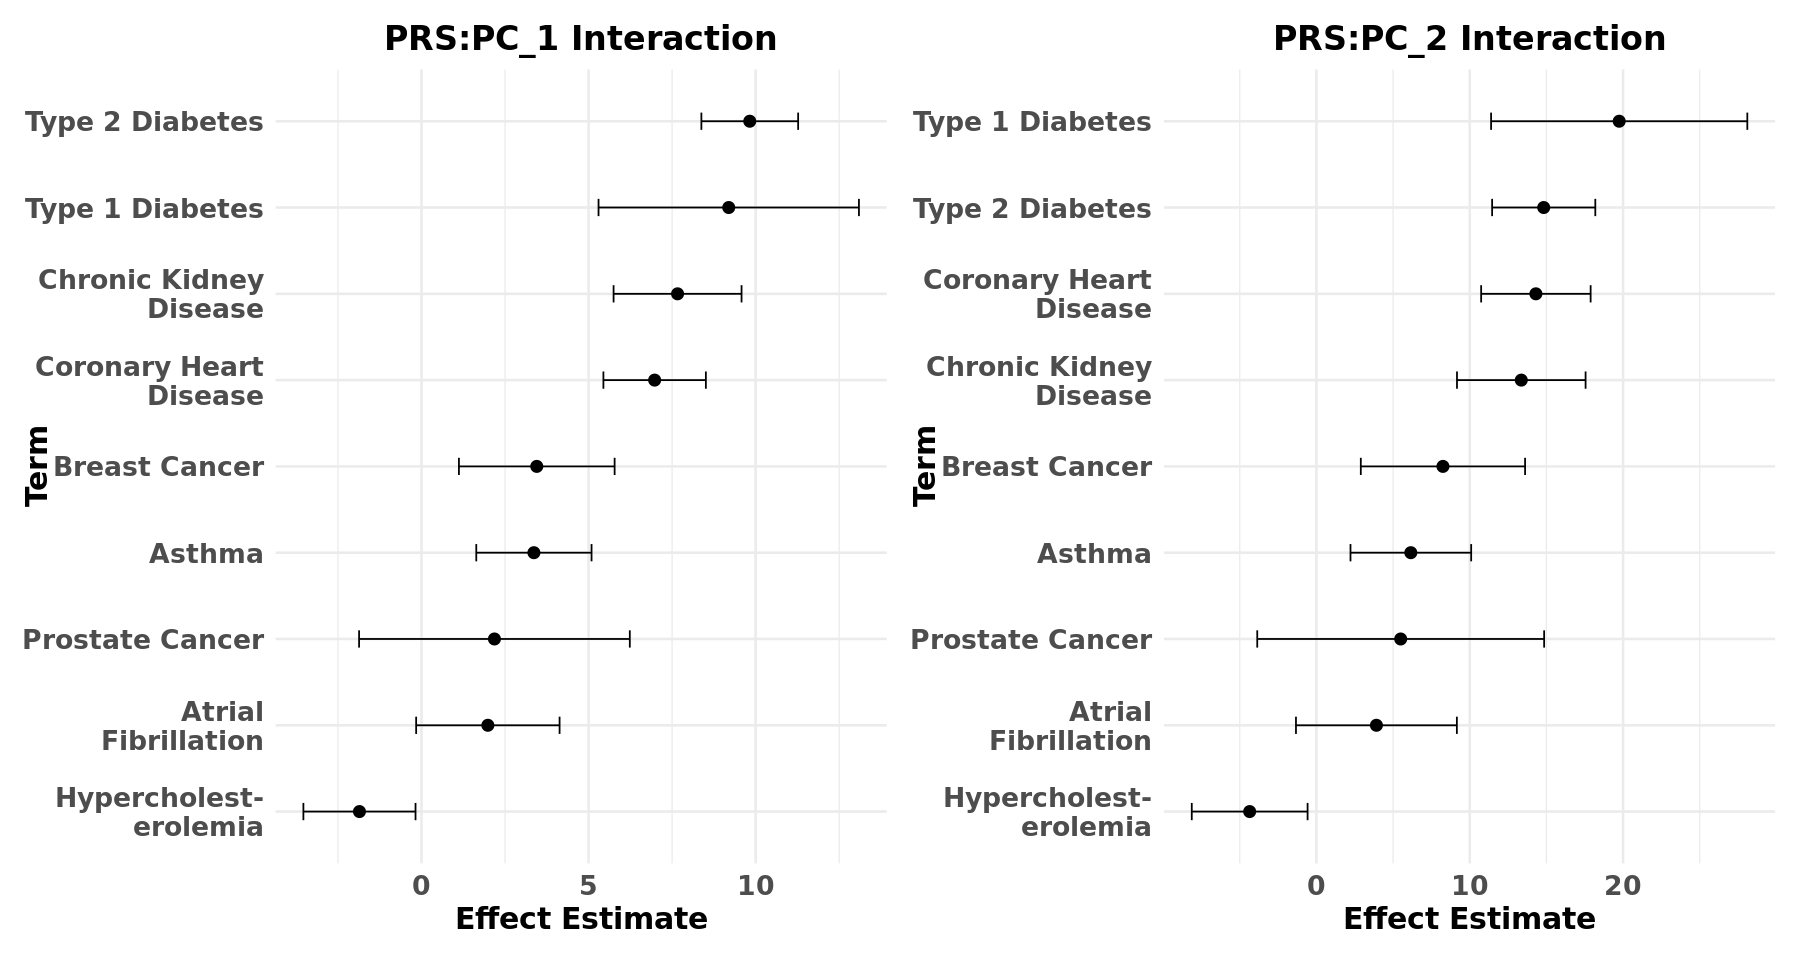

In [19]:
options(repr.plot.width = 15, repr.plot.height = 8)  # Set width and height


library(patchwork)

auc_plot_data_PRSPC1 <- auc_plot_data_PRSPC1 %>%
  mutate(
    CI_lower = estimate - 1.96 * std.error,
    CI_upper = estimate + 1.96 * std.error
  )

# Forest plot
PRSPC1<-ggplot(auc_plot_data_PRSPC1, aes(x = reorder(term, estimate), y = estimate)) +
  geom_point(size = 3) +
  geom_errorbar(aes(ymin = CI_lower, ymax = CI_upper), width = 0.2) +
  coord_flip() +
  labs(
    x = "Term",
    y = "Effect Estimate",
    title = "PRS:PC_1 Interaction"
  ) +
  theme_minimal(base_size = 16) +  # Increase base font size
  theme(
    text = element_text(color = "black", face = "bold"),     # Make all text bold and dark
    axis.title = element_text(size = 18),
    axis.text = element_text(size = 16),
    plot.title = element_text(size = 20, hjust = 0.5)
  )

auc_plot_data_PRSPC2 <- auc_plot_data_PRSPC2 %>%
  mutate(
    CI_lower = estimate - 1.96 * std.error,
    CI_upper = estimate + 1.96 * std.error
  )

# Forest plot
PRSPC2<-ggplot(auc_plot_data_PRSPC2, aes(x = reorder(term, estimate), y = estimate)) +
  geom_point(size = 3) +
  geom_errorbar(aes(ymin = CI_lower, ymax = CI_upper), width = 0.2) +
  coord_flip() +
  labs(
    x = "Term",
    y = "Effect Estimate",
    title = "PRS:PC_2 Interaction"
  ) +
  theme_minimal(base_size = 16) +  # Increase base font size
  theme(
    text = element_text(color = "black", face = "bold"),     # Make all text bold and dark
    axis.title = element_text(size = 18),
    axis.text = element_text(size = 16),
    plot.title = element_text(size = 20, hjust = 0.5)
  )

PRSPC1 + PRSPC2

In [20]:
long_prs <- merged_data %>%
  pivot_longer(
    cols = contains("_adjusted_score"),  # Select columns containing "_prs"
    names_to = "PRS",                # Name for the new column holding the original column names with "_prs_zscore"
    values_to = "value"              # Name for the new column holding the values
  )

plot_data <- long_prs %>%
  pivot_longer(
    cols = all_of(diseases),
    names_to = "disease",
    values_to = "disease_status"
  )

plot_data<-plot_data[substr(plot_data$PRS, 1, nchar(plot_data$disease)) == plot_data$disease, ]

plot_data <- plot_data %>%
  drop_na()


Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.”
Warning message:
“Groups with fewer than two data points have been dropped.”
Warning message in max(ids, na.rm = TRUE):
“no non-missing arguments to max; returning -Inf”


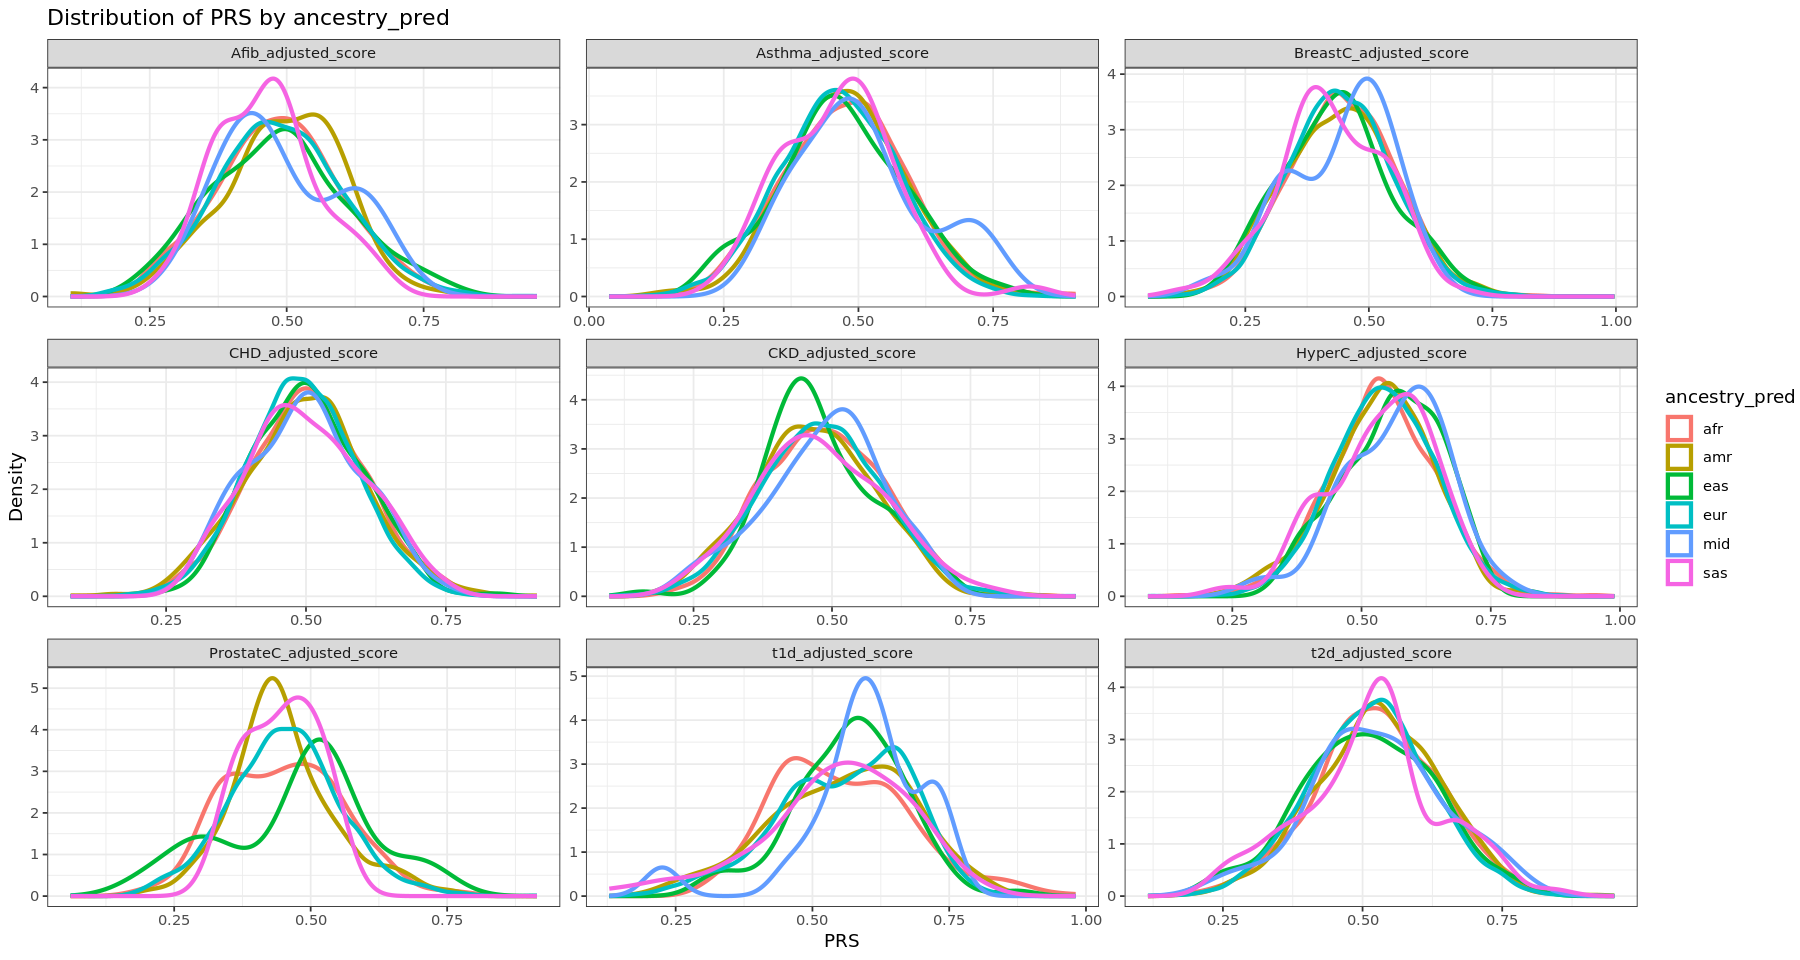

In [21]:
# Generate a single plot with facets for each disease and PRS combination
ggplot(plot_data, aes(x = value, color = ancestry_pred)) +
  geom_density(size = 1.2) +  # Thicker, colored lines
  facet_wrap(~ PRS, scales = "free") +  # Facet grid by disease
  theme_bw() +
  labs(
    x = "PRS", 
    y = "Density", 
    title = "Distribution of PRS by ancestry_pred"
  )

`geom_smooth()` using formula = 'y ~ x'


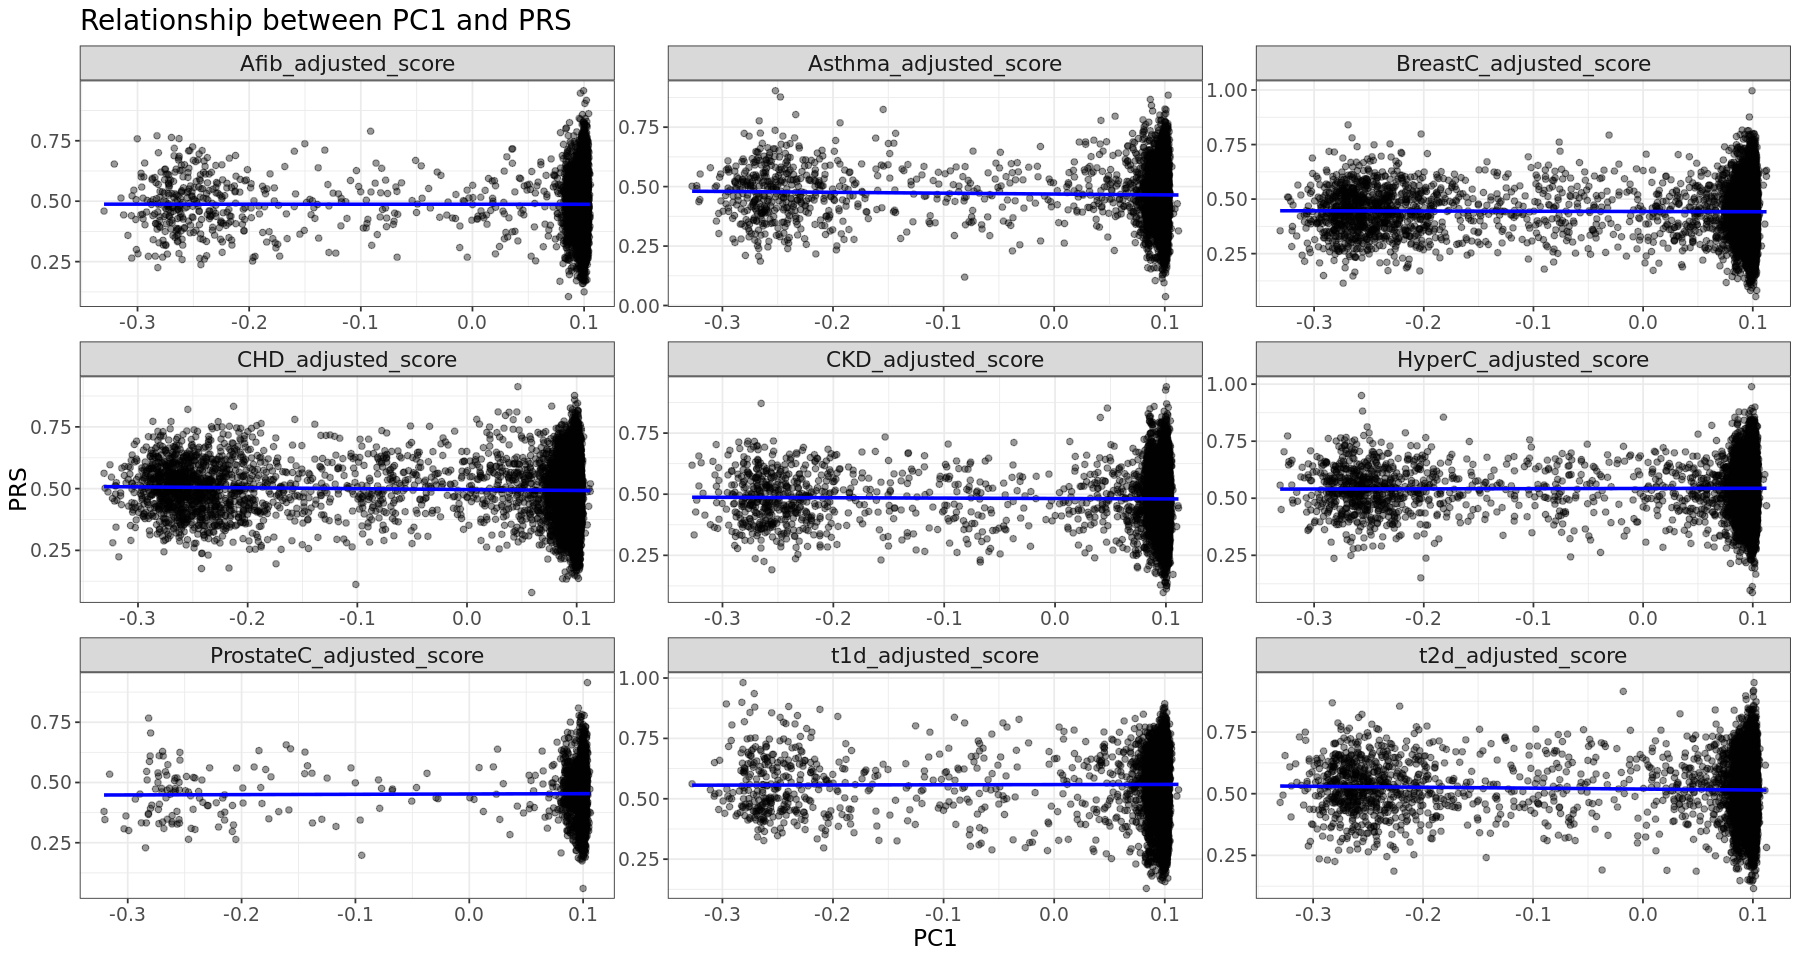

In [22]:
ggplot(plot_data, aes(x = PC_1, y = value)) +
  geom_point(alpha = 0.4, size = 1.5) +  # Adds scatter points
  geom_smooth(method = "lm", se = FALSE, color = "blue") +  # Optional trend line
  facet_wrap(~ PRS, scales = "free") +
  theme_bw() +
  labs(
    x = "PC1", 
    y = "PRS", 
    title = "Relationship between PC1 and PRS"
  ) +
  theme(
    text = element_text(size = 14),
    strip.text = element_text(size = 13)
  )


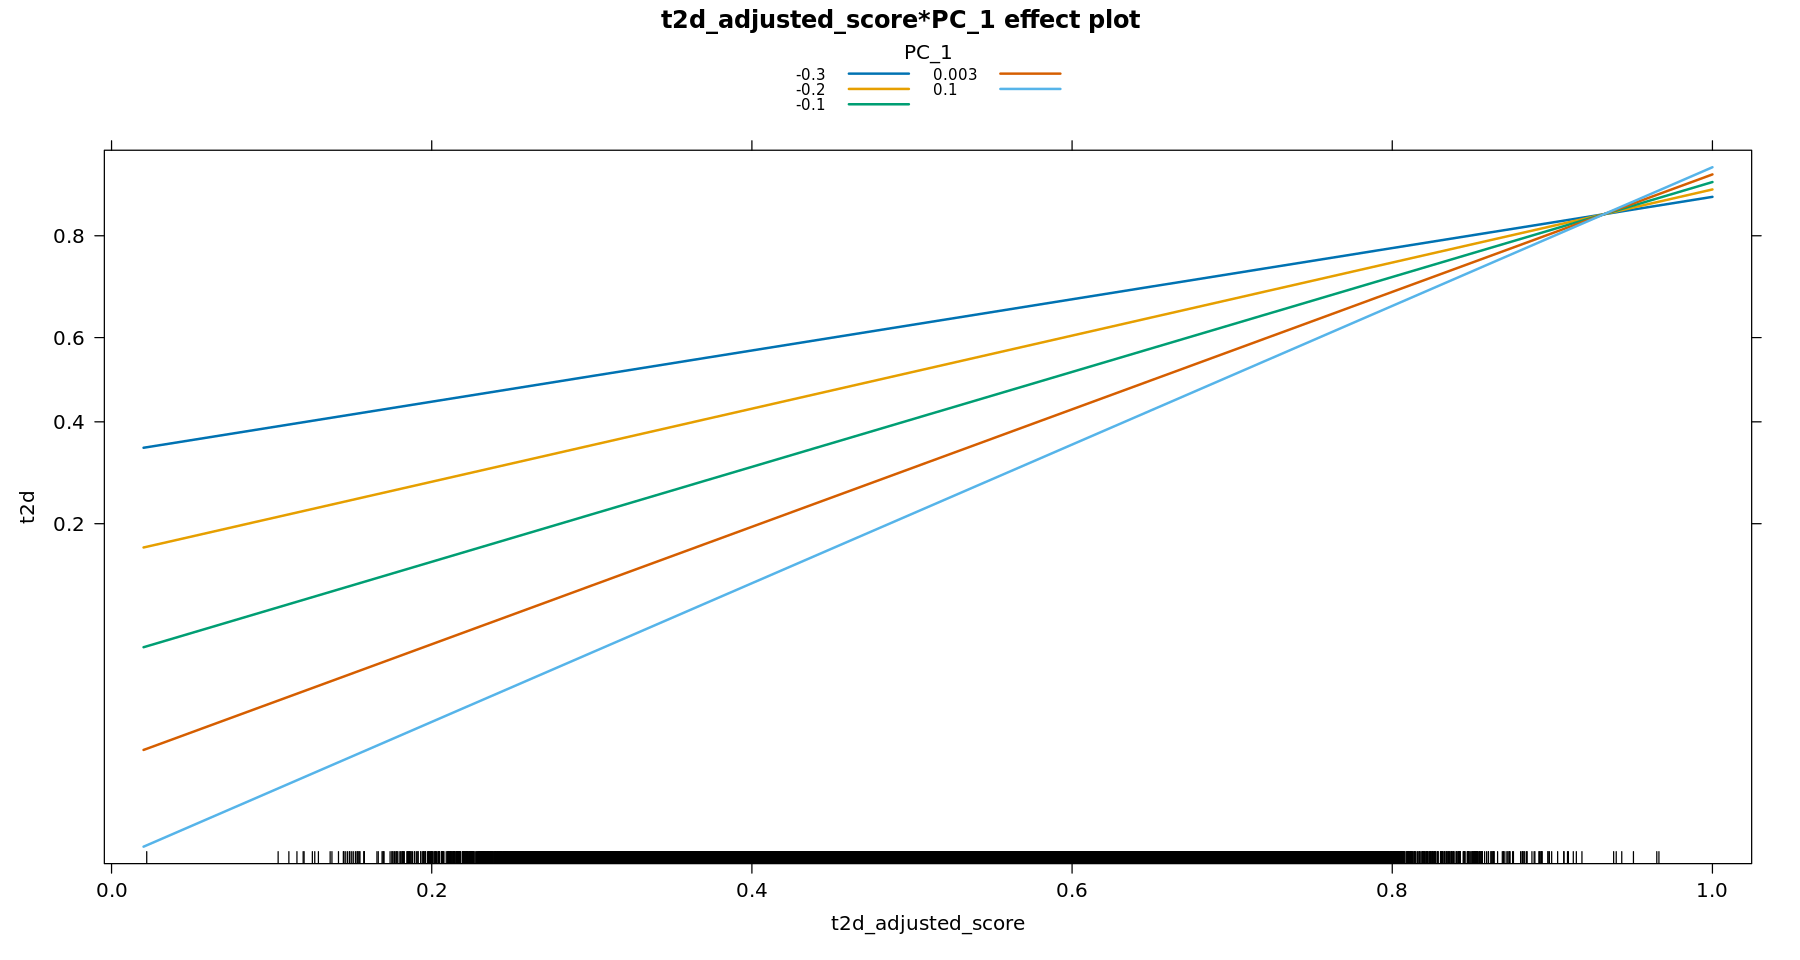

In [23]:
model<-glm(t2d ~ age + record_depth + visit_frequency + SexGenderCis_male + SexGenderSGM + 
           t2d_adjusted_score + PC_1 + t2d_adjusted_score:PC_1,
           data=merged_data, family=binomial)


plot(allEffects(model)[["t2d_adjusted_score:PC_1"]], multiline = TRUE)


# SDoH PC interactions

In [24]:
social_name_mapping1 <- c(
  "per_poverty_threshold:PC_1" = "Percent Poverty Threshold",
  "education:PC_1" = "Education",
  "assisted_income:PC_1" = "Assisted Income",
  "high_school_education:PC_1" = "High School Education",
  "median_income:PC_1" = "Median Income",
  "no_health_insurance:PC_1" = "No Health Insurance",
  "poverty:PC_1" = "Poverty", 
  "vacant_housing:PC_1" = "Vacant Housing",
  "deprivation_index:PC_1" = "Deprivation Index"
)

social_name_mapping2 <- c(
  "per_poverty_threshold:PC_2" = "Percent Poverty Threshold",
  "education:PC_2" = "Education",
  "assisted_income:PC_2" = "Assisted Income",
  "high_school_education:PC_2" = "High School Education",
  "median_income:PC_2" = "Median Income",
  "no_health_insurance:PC_2" = "No Health Insurance",
  "poverty:PC_2" = "Poverty", 
  "vacant_housing:PC_2" = "Vacant Housing",
  "deprivation_index:PC_2" = "Deprivation Index"
)

In [25]:
auc_plot_data_SocialPC1 <- auc_plot_data %>%
  filter(Model == "Social:PC_1") %>%
  select(-Domain) %>%
  distinct()

auc_plot_data_SocialPC2 <- auc_plot_data %>%
  filter(Model == "Social:PC_2") %>%
  select(-Domain) %>%
  distinct()


auc_plot_data_SocialPC1$term <- social_name_mapping1[auc_plot_data_SocialPC1$term]
auc_plot_data_SocialPC2$term <- social_name_mapping2[auc_plot_data_SocialPC2$term]

head(auc_plot_data_SocialPC1,20)

Disease,Model,term,estimate,std.error,statistic,p.value,PC_number
<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
Asthma,Social:PC_1,Percent Poverty Threshold,-1.3963024,0.8523371,-1.6382044,1.013791e-01,1
Asthma,Social:PC_1,Education,0.8310921,0.3168866,2.6226801,8.724114e-03,1
Asthma,Social:PC_1,Assisted Income,1.6913422,0.6607865,2.5595896,1.047958e-02,1
Asthma,Social:PC_1,High School Education,-1.9929089,0.7566834,-2.6337419,8.444966e-03,1
Asthma,Social:PC_1,Median Income,2.7701409,0.8552763,3.2388842,1.199983e-03,1
Asthma,Social:PC_1,No Health Insurance,0.5815359,0.7495301,0.7758672,4.378274e-01,1
Asthma,Social:PC_1,Poverty,-1.3562630,0.8550428,-1.5861932,1.126955e-01,1
Asthma,Social:PC_1,Vacant Housing,4.4352433,1.0020052,4.4263674,9.583326e-06,1
Asthma,Social:PC_1,Deprivation Index,0.8097766,0.7926487,1.0216085,3.069662e-01,1


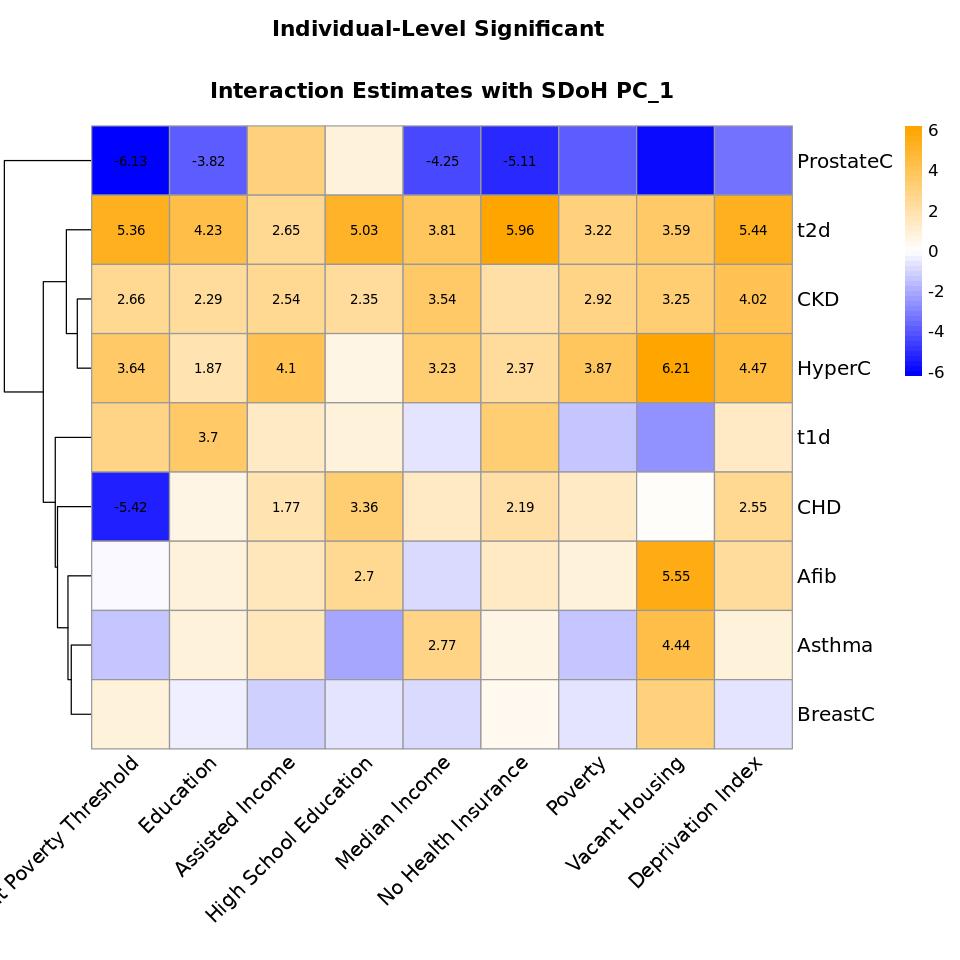

In [26]:
options(repr.plot.width = 8, repr.plot.height = 8)  # Set width and height


# Define column order for heatmap
x_axis_order <- c('Percent Poverty Threshold', 'Education', 'Assisted Income', 
                  'High School Education', 'Median Income', 
                  'No Health Insurance', 'Poverty', 'Vacant Housing', 'Deprivation Index')



# Wide format for coefficients (heatmap values)
heatmap_data_ind <- auc_plot_data_SocialPC1 %>%
  select(Disease, term, estimate) %>%
  pivot_wider(names_from = term, values_from = estimate) %>%
  column_to_rownames("Disease") %>%
  select(all_of(x_axis_order))

# Wide format for p-values (mask)
pvalue_data <- auc_plot_data_SocialPC1 %>%
  select(Disease, term, p.value) %>%
  pivot_wider(names_from = term, values_from = p.value) %>%
  column_to_rownames("Disease") %>%
  select(all_of(x_axis_order))

# Apply Bonferroni mask (significance threshold)
alpha <- 0.05 / (length(unique(results$Disease)) * length(terms))
significance_mask <- pvalue_data < alpha

# Format labels for display (only show significant values)
heatmap_labels_ind <- round(heatmap_data_ind, 2)
heatmap_labels_ind[!significance_mask] <- ""

# Create diverging color palette centered on 0
max_val <- max(abs(heatmap_data_ind), na.rm = TRUE)
breaks <- seq(-max_val, max_val, length.out = 51)
palette <- colorRampPalette(c("blue", "white", "orange"))(length(breaks) - 1)

# Plot the heatmap
ind_map<-pheatmap(
  mat = heatmap_data_ind,
  color = palette,
  breaks = breaks,
  cluster_rows = TRUE,
  cluster_cols = FALSE,
  display_numbers = heatmap_labels_ind,
  number_color = "black",
  fontsize_row = 12,
  fontsize_col = 12,
  angle_col = 45,
  main = "Individual-Level Significant \n
Interaction Estimates with SDoH PC_1",
  width = 3,
  height = 1
)

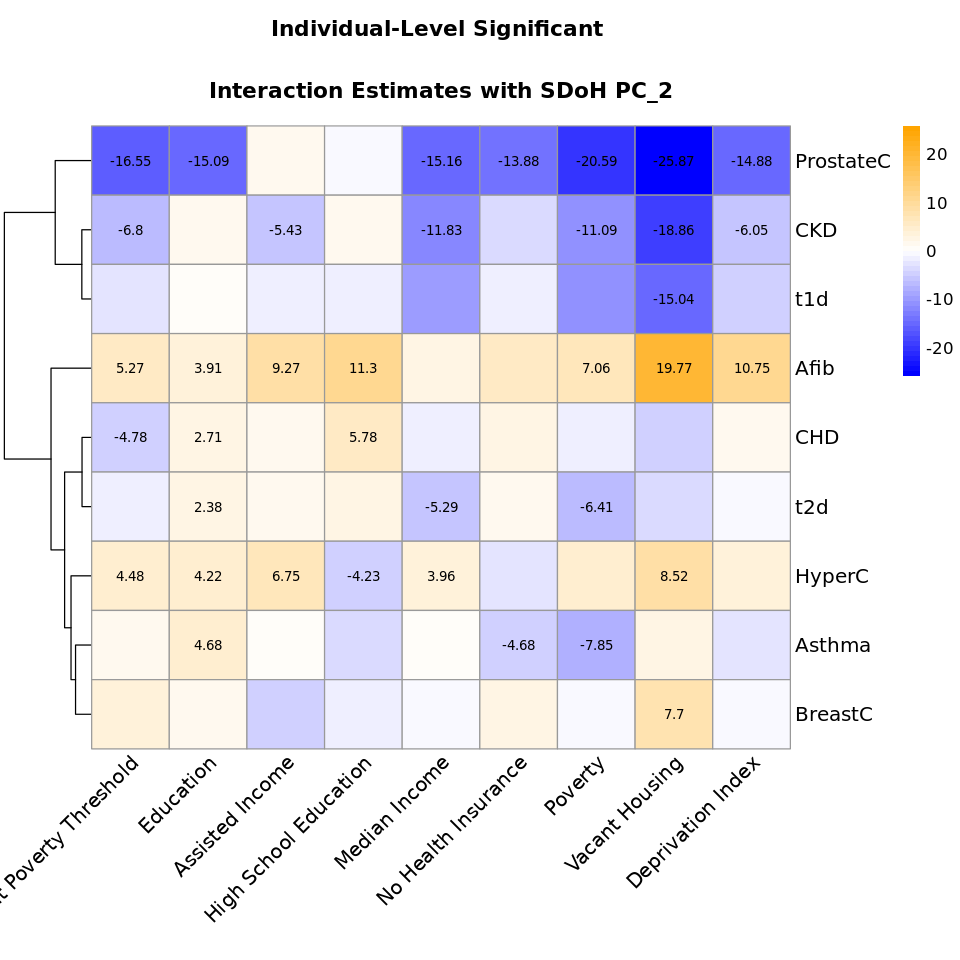

In [27]:
options(repr.plot.width = 8, repr.plot.height = 8)  # Set width and height


# Wide format for coefficients (heatmap values)
heatmap_data_ind <- auc_plot_data_SocialPC2 %>%
  select(Disease, term, estimate) %>%
  pivot_wider(names_from = term, values_from = estimate) %>%
  column_to_rownames("Disease") %>%
  select(all_of(x_axis_order))

# Wide format for p-values (mask)
pvalue_data <- auc_plot_data_SocialPC2 %>%
  select(Disease, term, p.value) %>%
  pivot_wider(names_from = term, values_from = p.value) %>%
  column_to_rownames("Disease") %>%
  select(all_of(x_axis_order))

# Apply Bonferroni mask (significance threshold)
alpha <- 0.05 / (length(unique(results$Disease)) * length(terms))
significance_mask <- pvalue_data < alpha

# Format labels for display (only show significant values)
heatmap_labels_ind <- round(heatmap_data_ind, 2)
heatmap_labels_ind[!significance_mask] <- ""

# Create diverging color palette centered on 0
max_val <- max(abs(heatmap_data_ind), na.rm = TRUE)
breaks <- seq(-max_val, max_val, length.out = 51)
palette <- colorRampPalette(c("blue", "white", "orange"))(length(breaks) - 1)

# Plot the heatmap
ind_map<-pheatmap(
  mat = heatmap_data_ind,
  color = palette,
  breaks = breaks,
  cluster_rows = TRUE,
  cluster_cols = FALSE,
  display_numbers = heatmap_labels_ind,
  number_color = "black",
  fontsize_row = 12,
  fontsize_col = 12,
  angle_col = 45,
  main = "Individual-Level Significant \n
Interaction Estimates with SDoH PC_2",
  width = 3,
  height = 1
)

# SDOH PRS Interactions

In [31]:
social_name_mapping <- c(
  "per_poverty_threshold" = "Percent Poverty Threshold",
  "education" = "Education",
  "assisted_income" = "Assisted Income",
  "high_school_education" = "High School Education",
  "median_income" = "Median Income",
  "no_health_insurance" = "No Health Insurance",
  "poverty" = "Poverty", 
  "vacant_housing" = "Vacant Housing",
  "deprivation_index" = "Deprivation Index"
)

disease_name_mapping <- c(
  "Asthma" = "Asthma",
    "Afib" = "Afib",
    "BreastC" = "BreastC",
    "CKD" = "CKD", 
    "CHD" = "CHD",
    "HyperC" = "HyperC",
    "ProstateC" = "ProstateC", 
  "t2d" = "T2D",
  "t1d" = "T1D"
)

auc_plot_data_PRSSocial <- auc_plot_data %>%
  filter(Model == "PRS:Social") %>%
  select(-Domain) %>%
  distinct()


auc_plot_data_PRSSocial <- auc_plot_data_PRSSocial %>%
  mutate(
    PRS    = str_split_fixed(term, ":", 2)[,1],
    Social = str_split_fixed(term, ":", 2)[,2]
  )

auc_plot_data_PRSSocial$Social <- social_name_mapping[auc_plot_data_PRSSocial$Social]
auc_plot_data_PRSSocial$Disease <- disease_name_mapping[auc_plot_data_PRSSocial$Disease]



head(auc_plot_data_PRSSocial,20)

Disease,Model,term,estimate,std.error,statistic,p.value,PC_number,PRS,Social
<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>
Asthma,PRS:Social,Asthma_adjusted_score:per_poverty_threshold,-2.1940210,0.6966158,-3.1495425,1.635263e-03,NA,Asthma_adjusted_score,Percent Poverty Threshold
Asthma,PRS:Social,Asthma_adjusted_score:education,-1.5495265,0.3972245,-3.9008838,9.584214e-05,NA,Asthma_adjusted_score,Education
Asthma,PRS:Social,Asthma_adjusted_score:assisted_income,-0.6569343,0.8394899,-0.7825399,4.338973e-01,NA,Asthma_adjusted_score,Assisted Income
Asthma,PRS:Social,Asthma_adjusted_score:high_school_education,-0.3050697,0.9024140,-0.3380596,7.353183e-01,NA,Asthma_adjusted_score,High School Education
Asthma,PRS:Social,Asthma_adjusted_score:median_income,-0.8644044,0.9528591,-0.9071691,3.643174e-01,NA,Asthma_adjusted_score,Median Income
Asthma,PRS:Social,Asthma_adjusted_score:no_health_insurance,-0.7597214,0.8968468,-0.8471028,3.969379e-01,NA,Asthma_adjusted_score,No Health Insurance
Asthma,PRS:Social,Asthma_adjusted_score:poverty,-0.4725504,1.0770601,-0.4387410,6.608492e-01,NA,Asthma_adjusted_score,Poverty
Asthma,PRS:Social,Asthma_adjusted_score:vacant_housing,-1.1701894,1.2594247,-0.9291460,3.528134e-01,NA,Asthma_adjusted_score,Vacant Housing
Asthma,PRS:Social,Asthma_adjusted_score:deprivation_index,-0.8573980,0.9545237,-0.8982469,3.690539e-01,NA,Asthma_adjusted_score,Deprivation Index


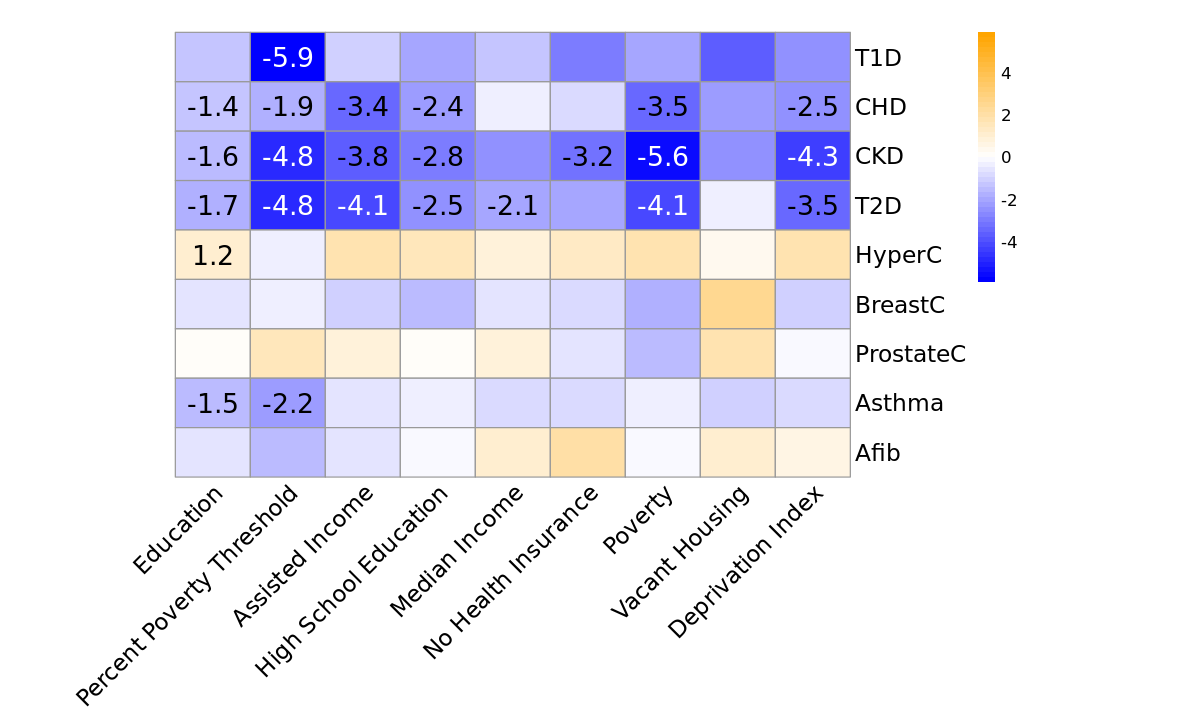

In [37]:
# Define column order for heatmap
x_axis_order <- c('Education', 'Percent Poverty Threshold', 'Assisted Income', 
                  'High School Education', 'Median Income', 
                  'No Health Insurance', 'Poverty', 'Vacant Housing', 'Deprivation Index')



# Wide format for coefficients (heatmap values)
heatmap_data_ind <- auc_plot_data_PRSSocial %>%
  select(Disease, Social, estimate) %>%
  pivot_wider(names_from = Social, values_from = estimate) %>%
  column_to_rownames("Disease") %>%
  select(all_of(x_axis_order))

# Wide format for p-values (mask)
pvalue_data <- auc_plot_data_PRSSocial %>%
  select(Disease, Social, p.value) %>%
  pivot_wider(names_from = Social, values_from = p.value) %>%
  column_to_rownames("Disease") %>%
  select(all_of(x_axis_order))

# Apply Bonferroni mask (significance threshold)
alpha <- 0.05 / (length(unique(results$Disease)) * length(terms))
significance_mask <- pvalue_data < alpha

# Format labels for display (only show significant values)
heatmap_labels_ind <- round(heatmap_data_ind, 1)
heatmap_labels_ind[!significance_mask] <- ""

# Create diverging color palette centered on 0
max_val <- max(abs(heatmap_data_ind), na.rm = TRUE)
breaks <- seq(-max_val, max_val, length.out = 51)
color_palette <- colorRampPalette(c("blue", "white", "orange"))(length(breaks) - 1)  # Diverging colors

number_colors <- matrix("black", nrow = nrow(heatmap_data_ind), ncol = ncol(heatmap_data_ind))
number_colors[heatmap_data_ind < -4] <- "white"

heatmap_mat <- as.matrix(heatmap_data_ind)

# Compute row clustering to get row order
row_clust  <- hclust(dist(heatmap_mat))
row_order  <- row_clust$order

# Reorder EVERYTHING to this order; keep your custom column order already set
heatmap_mat_ord        <- heatmap_mat[row_order, , drop = FALSE]
heatmap_labels_ord     <- heatmap_labels_ind[row_order, , drop = FALSE]
number_colors_ord      <- number_colors[row_order, , drop = FALSE]


ind_map <- pheatmap(
  heatmap_mat_ord,
  color = palette,  # Diverging color scale
  breaks = breaks,  # Center scale at 0
  cluster_rows = FALSE,  # Cluster diseases
  cluster_cols = FALSE,  # Keep columns in specified order
  main = "",
  fontsize_row = 14,  # Font size for row labels
  fontsize_col = 14,  # Font size for column labels
  display_numbers = heatmap_labels_ord,  # Show effect sizes in cells
  number_color = number_colors_ord,  # Color of the numbers
  number_format = "%.2f",  # Format for numbers in cells
  fontsize_number = 16,
  height = 1,  # Increase vertical size of the heatmap
  width = 2,
  angle_col = 45,
  cellwidth = 45              # widen cells so angled labels fit
)

options(repr.plot.width = 10, repr.plot.height = 6)  # Set width and height


# SDOH PRS Interactions control for PCs

In [30]:
# Function to generate formulas for disease-domain pairs
generate_formulas <- function(disease, domain, model, PC) {
  # Base covariates
  covariates <- c("age", "age2", "record_depth", "visit_frequency", paste0("PC_", 1:16))
  
  # All possible sex terms
  sex_terms <- c("SexGenderCis_male", "SexGenderSGM")
  
  # Disease-specific exclusions
  if (disease == "CKD" || disease == "t1d") {
    sex_terms <- setdiff(sex_terms, "SexGenderSGM")
  }
  if (disease == "BreastC") {
    sex_terms <- setdiff(sex_terms, "SexGenderCis_male")
  }
  if (disease == "ProstateC") {
    sex_terms <- setdiff(sex_terms, "SexGenderCis_male")
  }

  # Combine covariates
  base <- paste(c(covariates, sex_terms), collapse = " + ")
  score <- paste0(disease, "_adjusted_score")
  prcomp <- PC
  prspc <- paste0(score, ":", PC)
  socialpc <- paste0(domain, ":", PC)
  prssocial <- paste0(score, ":", domain)

  # Return all 5 models
  list(
    as.formula(paste(disease, "~", paste(c(base, score, prcomp, prspc), collapse = " + "))),
    as.formula(paste(disease, "~", paste(c(base, domain, prcomp, socialpc), collapse = " + "))),
    as.formula(paste(disease, "~", paste(c(base, score, domain, prssocial), collapse = " + ")))

  )
}

# Step 1: Generate combinations of diseases and domains
combinations <- expand_grid(
  disease = unlist(diseases),
  domain = domains,
    PC = PCs
)

# Step 2: Generate formulas and fit models
results2 <- combinations %>%
  rowwise() %>%
  mutate(
    formulas = list(generate_formulas(disease, domain, model=NULL, PC)),
    model_results = list(fit_and_extract(formulas, disease, domain, models, merged_data))
  ) %>%
  ungroup() %>%
  select(model_results) %>%
  unnest(model_results)

# Step 3: Clean and arrange results
results2 <- results %>%
  select(Disease, Domain, Model, term, estimate, std.error, statistic, p.value, AUC, AUC_CI_Lower, AUC_CI_Upper)

# Print results
head(results2)

Warning message:
“There were 108 warnings in `mutate()`.
The first warning was:
ℹ In argument: `model_results = list(fit_and_extract(formulas, disease, domain,
  models, merged_data))`.
ℹ In row 1.
Caused by warning:
! glm.fit: fitted probabilities numerically 0 or 1 occurred
ℹ Run `dplyr::last_dplyr_warnings()` to see the 107 remaining warnings.”


Disease,Domain,Model,term,estimate,std.error,statistic,p.value,AUC,AUC_CI_Lower,AUC_CI_Upper
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Asthma,per_poverty_threshold,PRS:PC,(Intercept),-2.8426770110,1.482339e-01,-19.176975,5.763782e-82,0.828083,0.8233137,0.8328523
Asthma,per_poverty_threshold,PRS:PC,age,0.0389261627,5.449769e-03,7.142718,9.150319e-13,0.828083,0.8233137,0.8328523
Asthma,per_poverty_threshold,PRS:PC,age2,-0.0004869334,5.196343e-05,-9.370694,7.205743e-21,0.828083,0.8233137,0.8328523
Asthma,per_poverty_threshold,PRS:PC,record_depth,0.0134582592,2.672672e-04,50.355075,0.000000e+00,0.828083,0.8233137,0.8328523
Asthma,per_poverty_threshold,PRS:PC,visit_frequency,-4.8996999740,9.603625e-01,-5.101928,3.362113e-07,0.828083,0.8233137,0.8328523
Asthma,per_poverty_threshold,PRS:PC,SexGenderCis_male,-0.7481605067,3.103151e-02,-24.109704,1.977530e-128,0.828083,0.8233137,0.8328523


In [30]:
auc_plot_data <- results2 %>%
  filter(str_detect(term, ":")) %>%  # Keep terms that include an interaction
  filter(!is.na(AUC)) %>%
  select(Disease, Domain, Model, term, estimate, std.error, statistic, p.value) %>%
  distinct()


social_name_mapping <- c(
  "per_poverty_threshold" = "Percent Poverty Threshold",
  "education" = "Education",
  "assisted_income" = "Assisted Income",
  "high_school_education" = "High School Education",
  "median_income" = "Median Income",
  "no_health_insurance" = "No Health Insurance",
  "poverty" = "Poverty", 
  "vacant_housing" = "Vacant Housing",
  "deprivation_index" = "Deprivation Index"
)


auc_plot_data_PRSSocial <- auc_plot_data %>%
  filter(Model == "PRS:Social") %>%
  select(-Domain) %>%
  distinct()


auc_plot_data_PRSSocial <- auc_plot_data_PRSSocial %>%
  mutate(
    PRS    = str_split_fixed(term, ":", 2)[,1],
    Social = str_split_fixed(term, ":", 2)[,2]
  )

auc_plot_data_PRSSocial$Social <- social_name_mapping[auc_plot_data_PRSSocial$Social]
auc_plot_data_PRSSocial$Disease <- disease_name_mapping[auc_plot_data_PRSSocial$Disease]


head(auc_plot_data_PRSSocial,20)

ERROR: Error: object 'results2' not found


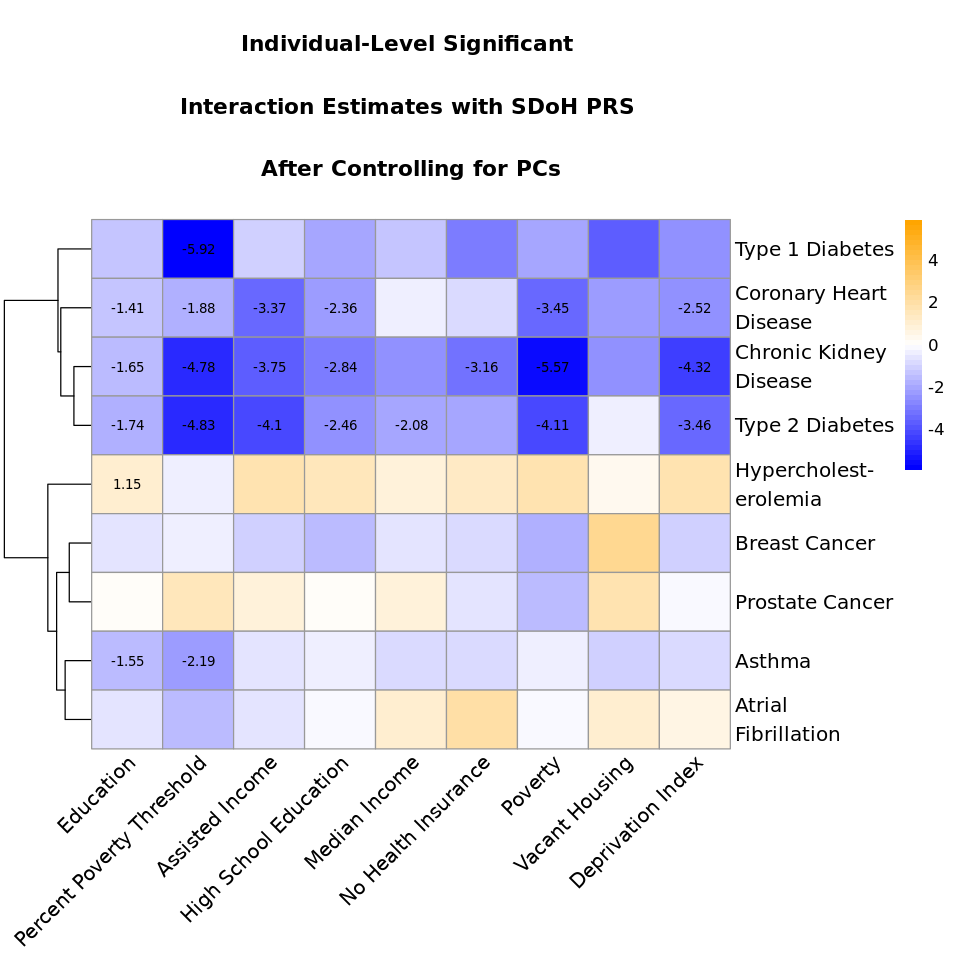

In [32]:



# Define column order for heatmap
x_axis_order <- c('Education', 'Percent Poverty Threshold', 'Assisted Income', 
                  'High School Education', 'Median Income', 
                  'No Health Insurance', 'Poverty', 'Vacant Housing', 'Deprivation Index')



# Wide format for coefficients (heatmap values)
heatmap_data_ind <- auc_plot_data_PRSSocial %>%
  select(Disease, Social, estimate) %>%
  pivot_wider(names_from = Social, values_from = estimate) %>%
  column_to_rownames("Disease") %>%
  select(all_of(x_axis_order))

# Wide format for p-values (mask)
pvalue_data <- auc_plot_data_PRSSocial %>%
  select(Disease, Social, p.value) %>%
  pivot_wider(names_from = Social, values_from = p.value) %>%
  column_to_rownames("Disease") %>%
  select(all_of(x_axis_order))

# Apply Bonferroni mask (significance threshold)
alpha <- 0.05 / (length(unique(results$Disease)) * length(terms))
significance_mask <- pvalue_data < alpha

# Format labels for display (only show significant values)
heatmap_labels_ind <- round(heatmap_data_ind, 2)
heatmap_labels_ind[!significance_mask] <- ""

# Create diverging color palette centered on 0
max_val <- max(abs(heatmap_data_ind), na.rm = TRUE)
breaks <- seq(-max_val, max_val, length.out = 51)
palette <- colorRampPalette(c("blue", "white", "orange"))(length(breaks) - 1)

# Plot the heatmap
ind_map<-pheatmap(
  mat = heatmap_data_ind,
  color = palette,
  breaks = breaks,
  cluster_rows = TRUE,
  cluster_cols = FALSE,
  display_numbers = heatmap_labels_ind,
  number_color = "black",
  fontsize_row = 12,
  fontsize_col = 12,
  angle_col = 45,
  main = "Individual-Level Significant \n
Interaction Estimates with SDoH PRS \n
After Controlling for PCs",
  width = 3,
  height = 1
)

In [33]:
merged_data2<-merged_data #|> filter(ancestry_pred == "afr")

In [84]:
merged_data2 <- merged_data %>%
  mutate(
    SIRE = case_when(
      Black == 1 & His == 0 ~ "NH Black",
      White == 1 & His == 0 ~ "NH White",
      His == 1 ~ "HS",
      Asian == 1 | PI == 1 ~ "AANHPI",
      TRUE ~ NA
    )
  )

In [76]:
names(merged_data2)

[1] "person_id"                     "Asthma_adjusted_score"        
  [3] "Afib_adjusted_score"           "BreastC_adjusted_score"       
  [5] "CKD_adjusted_score"            "CHD_adjusted_score"           
  [7] "HyperC_adjusted_score"         "ProstateC_adjusted_score"     
  [9] "t1d_adjusted_score"            "t2d_adjusted_score"           
 [11] "Asthma"                        "Afib"                         
 [13] "BreastC"                       "CKD"                          
 [15] "CHD"                           "HyperC"                       
 [17] "ProstateC"                     "t2d"                          
 [19] "t1d"                           "date_of_birth"                
 [21] "AIAN"                          "Asian"                        
 [23] "Black"                         "Mid"                          
 [25] "Multiple"                      "PI"                           
 [27] "White"                         "His"                          
 [29] "race_unknown"                  "SexGender"                    
 [31] "age_today"                     "ancestry_pred"                
 [33] "PC_1"                          "PC_2"                         
 [35] "PC_3"                          "PC_4"                         
 [37] "PC_5"                          "PC_6"                         
 [39] "PC_7"                          "PC_8"                         
 [41] "PC_9"                          "PC_10"                        
 [43] "PC_11"                         "PC_12"                        
 [45] "PC_13"                         "PC_14"                        
 [47] "PC_15"                         "PC_16"                        
 [49] "where_born"                    "military"                     
 [51] "healthcare"                    "disabled"                     
 [53] "sexual_orientation"            "LGBTQIA"                      
 [55] "min_date"                      "max_date"                     
 [57] "ehr_length"                    "relative_health"              
 [59] "record_depth"                  "visit_frequency"              
 [61] "age"                           "record_depth_winsorized"      
 [63] "visit_frequency_winsorized"    "education"                    
 [65] "employment"                    "income"                       
 [67] "home_own"                      "number_living"                
 [69] "median_adjusted_income"        "number_living_adjusted_income"
 [71] "income_adjusted_both"          "health_literacy"              
 [73] "housing_quality"               "housing_instability"          
 [75] "food_insecurity"               "Walkability"                  
 [77] "loneliness"                    "crime_saftey"                 
 [79] "npd_scale"                     "nsd_scale"                    
 [81] "discrimination"                "health_discrim"               
 [83] "social_cohesion"               "stress"                       
 [85] "social_support"                "spirituality"                 
 [87] "health_coverage"               "health_care_use"              
 [89] "delayed_care"                  "afford_care"                  
 [91] "worried_pay"                   "respect"                      
 [93] "housing_type"                  "per_poverty_threshold"        
 [95] "assisted_income"               "high_school_education"        
 [97] "median_income"                 "no_health_insurance"          
 [99] "poverty"                       "vacant_housing"               
[101] "deprivation_index"             "age2"                         
[103] "SexGenderCis_male"             "SexGenderCis_female"          
[105] "SexGenderSGM"                  "SIRE"

In [77]:
model<-glm(t2d ~ age + record_depth + visit_frequency + SexGenderCis_male + SexGenderSGM + 
           t2d_adjusted_score + deprivation_index + PC_1 + t2d_adjusted_score:PC_1,
           data=merged_data2, family=binomial)


plot_1<-plot(allEffects(model)[["t2d_adjusted_score:PC_1"]], multiline = TRUE)


In [78]:
model<-glm(t2d ~ age + record_depth + visit_frequency + SexGenderCis_male + SexGenderSGM + 
           t2d_adjusted_score + deprivation_index + PC_1 + t2d_adjusted_score:deprivation_index,
           data=merged_data2, family=binomial)


plot_2<-plot(allEffects(model)[["t2d_adjusted_score:deprivation_index"]], multiline = TRUE)

In [85]:
model<-glm(t2d ~ age + record_depth + visit_frequency + SexGenderCis_male + SexGenderSGM + 
           t2d_adjusted_score + SIRE + deprivation_index + SIRE:deprivation_index,
           data=merged_data2, family=binomial)


plot_3<-plot(allEffects(model)[["SIRE:deprivation_index"]], multiline = TRUE)

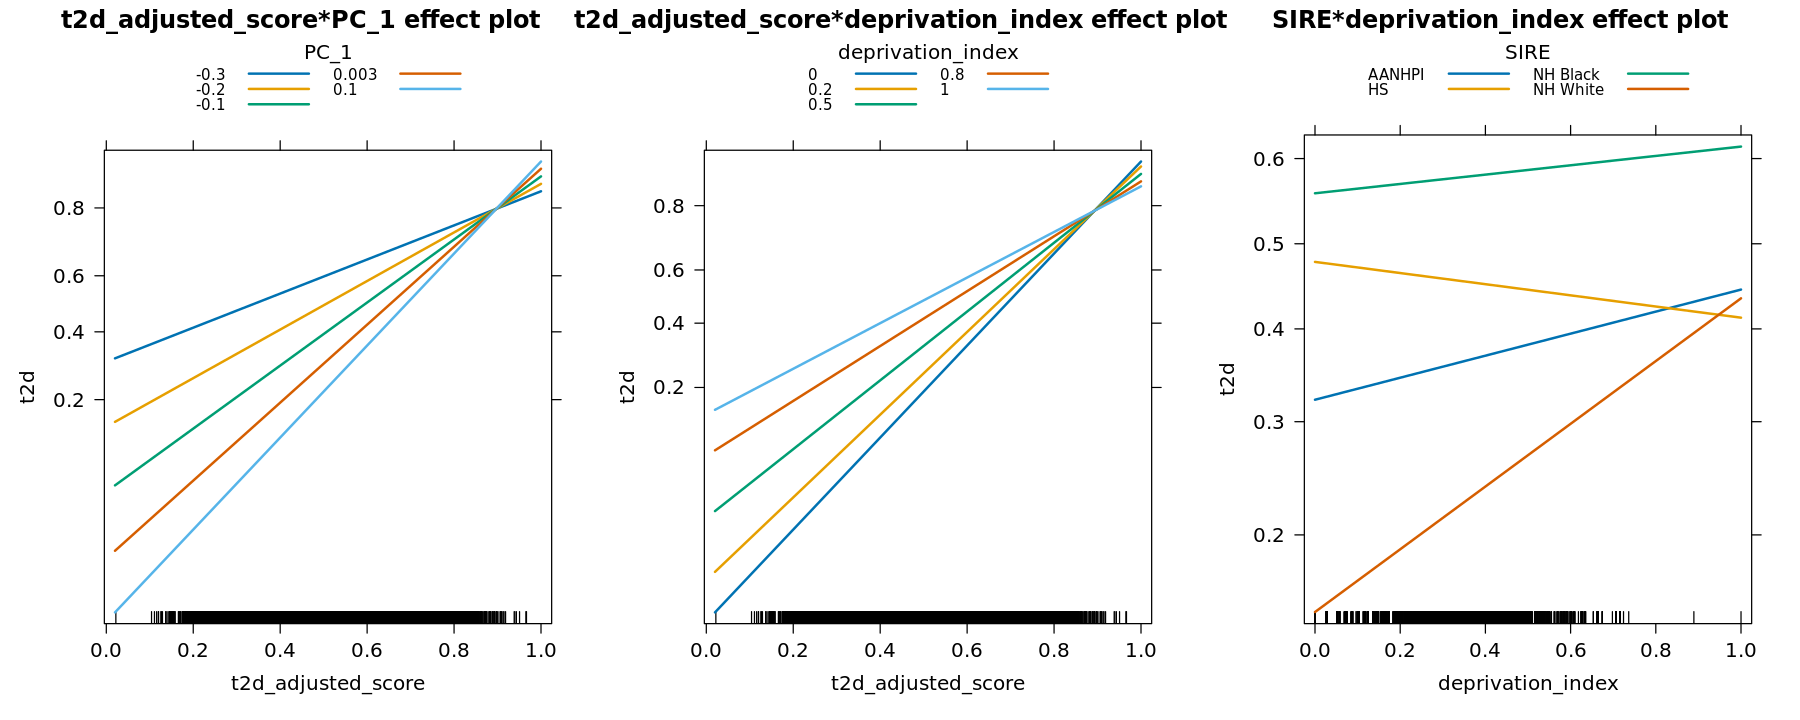

In [86]:
options(repr.plot.width = 15, repr.plot.height = 6)  # Set width and height

library(gridExtra)

grid.arrange(plot_1, plot_2, plot_3, ncol = 3)

# Plot grid of PRS*SDoH interactions

## T2D

In [50]:
model<-glm(t2d ~ age + record_depth + visit_frequency + SexGenderCis_male + SexGenderSGM + 
           t2d_adjusted_score + per_poverty_threshold + t2d_adjusted_score:per_poverty_threshold,
           data=merged_data2, family=binomial)

plot_t2d_ppt <- plot(allEffects(model)[["t2d_adjusted_score:per_poverty_threshold"]], multiline = TRUE)

model<-glm(t2d ~ age + record_depth + visit_frequency + SexGenderCis_male + SexGenderSGM + 
           t2d_adjusted_score + education + t2d_adjusted_score:education,
           data=merged_data2, family=binomial)

plot_t2d_edu <- plot(allEffects(model)[["t2d_adjusted_score:education"]], multiline = TRUE)

model<-glm(t2d ~ age + record_depth + visit_frequency + SexGenderCis_male + SexGenderSGM + 
           t2d_adjusted_score + assisted_income + t2d_adjusted_score:assisted_income,
           data=merged_data2, family=binomial)

plot_t2d_ain <- plot(allEffects(model)[["t2d_adjusted_score:assisted_income"]], multiline = TRUE)

model<-glm(t2d ~ age + record_depth + visit_frequency + SexGenderCis_male + SexGenderSGM + 
           t2d_adjusted_score + high_school_education + t2d_adjusted_score:high_school_education,
           data=merged_data2, family=binomial)

plot_t2d_area_edu <- plot(allEffects(model)[["t2d_adjusted_score:high_school_education"]], multiline = TRUE)


model<-glm(t2d ~ age + record_depth + visit_frequency + SexGenderCis_male + SexGenderSGM + 
           t2d_adjusted_score + poverty + t2d_adjusted_score:poverty,
           data=merged_data2, family=binomial)

plot_t2d_poverty <- plot(allEffects(model)[["t2d_adjusted_score:poverty"]], multiline = TRUE)


model<-glm(t2d ~ age + record_depth + visit_frequency + SexGenderCis_male + SexGenderSGM + 
           t2d_adjusted_score + deprivation_index + t2d_adjusted_score:deprivation_index,
           data=merged_data2, family=binomial)


plot_t2d_dep <- plot(allEffects(model)[["t2d_adjusted_score:deprivation_index"]], multiline = TRUE)


In [51]:
model<-glm(CKD ~ age + record_depth + visit_frequency + SexGenderCis_male + SexGenderSGM + 
           CKD_adjusted_score + per_poverty_threshold + CKD_adjusted_score:per_poverty_threshold,
           data=merged_data2, family=binomial)

plot_CKD_ppt <- plot(allEffects(model)[["CKD_adjusted_score:per_poverty_threshold"]], multiline = TRUE)

model<-glm(CKD ~ age + record_depth + visit_frequency + SexGenderCis_male + SexGenderSGM + 
           CKD_adjusted_score + education + CKD_adjusted_score:education,
           data=merged_data2, family=binomial)

plot_CKD_edu <- plot(allEffects(model)[["CKD_adjusted_score:education"]], multiline = TRUE)

model<-glm(CKD ~ age + record_depth + visit_frequency + SexGenderCis_male + SexGenderSGM + 
           CKD_adjusted_score + assisted_income + CKD_adjusted_score:assisted_income,
           data=merged_data2, family=binomial)

plot_CKD_ain <- plot(allEffects(model)[["CKD_adjusted_score:assisted_income"]], multiline = TRUE)

model<-glm(CKD ~ age + record_depth + visit_frequency + SexGenderCis_male + SexGenderSGM + 
           CKD_adjusted_score + high_school_education + CKD_adjusted_score:high_school_education,
           data=merged_data2, family=binomial)

plot_CKD_area_edu <- plot(allEffects(model)[["CKD_adjusted_score:high_school_education"]], multiline = TRUE)


model<-glm(CKD ~ age + record_depth + visit_frequency + SexGenderCis_male + SexGenderSGM + 
           CKD_adjusted_score + poverty + CKD_adjusted_score:poverty,
           data=merged_data2, family=binomial)

plot_CKD_poverty <- plot(allEffects(model)[["CKD_adjusted_score:poverty"]], multiline = TRUE)


model<-glm(CKD ~ age + record_depth + visit_frequency + SexGenderCis_male + SexGenderSGM + 
           CKD_adjusted_score + deprivation_index + CKD_adjusted_score:deprivation_index,
           data=merged_data2, family=binomial)


plot_CKD_dep <- plot(allEffects(model)[["CKD_adjusted_score:deprivation_index"]], multiline = TRUE)


In [52]:
model<-glm(CHD ~ age + record_depth + visit_frequency + SexGenderCis_male + SexGenderSGM + 
           CHD_adjusted_score + per_poverty_threshold + CHD_adjusted_score:per_poverty_threshold,
           data=merged_data2, family=binomial)

plot_CHD_ppt <- plot(allEffects(model)[["CHD_adjusted_score:per_poverty_threshold"]], multiline = TRUE)

model<-glm(CHD ~ age + record_depth + visit_frequency + SexGenderCis_male + SexGenderSGM + 
           CHD_adjusted_score + education + CHD_adjusted_score:education,
           data=merged_data2, family=binomial)

plot_CHD_edu <- plot(allEffects(model)[["CHD_adjusted_score:education"]], multiline = TRUE)

model<-glm(CHD ~ age + record_depth + visit_frequency + SexGenderCis_male + SexGenderSGM + 
           CHD_adjusted_score + assisted_income + CHD_adjusted_score:assisted_income,
           data=merged_data2, family=binomial)

plot_CHD_ain <- plot(allEffects(model)[["CHD_adjusted_score:assisted_income"]], multiline = TRUE)

model<-glm(CHD ~ age + record_depth + visit_frequency + SexGenderCis_male + SexGenderSGM + 
           CHD_adjusted_score + high_school_education + CHD_adjusted_score:high_school_education,
           data=merged_data2, family=binomial)

plot_CHD_area_edu <- plot(allEffects(model)[["CHD_adjusted_score:high_school_education"]], multiline = TRUE)


model<-glm(CHD ~ age + record_depth + visit_frequency + SexGenderCis_male + SexGenderSGM + 
           CHD_adjusted_score + poverty + CHD_adjusted_score:poverty,
           data=merged_data2, family=binomial)

plot_CHD_poverty <- plot(allEffects(model)[["CHD_adjusted_score:poverty"]], multiline = TRUE)


model<-glm(CHD ~ age + record_depth + visit_frequency + SexGenderCis_male + SexGenderSGM + 
           CHD_adjusted_score + deprivation_index + CHD_adjusted_score:deprivation_index,
           data=merged_data2, family=binomial)


plot_CHD_dep <- plot(allEffects(model)[["CHD_adjusted_score:deprivation_index"]], multiline = TRUE)


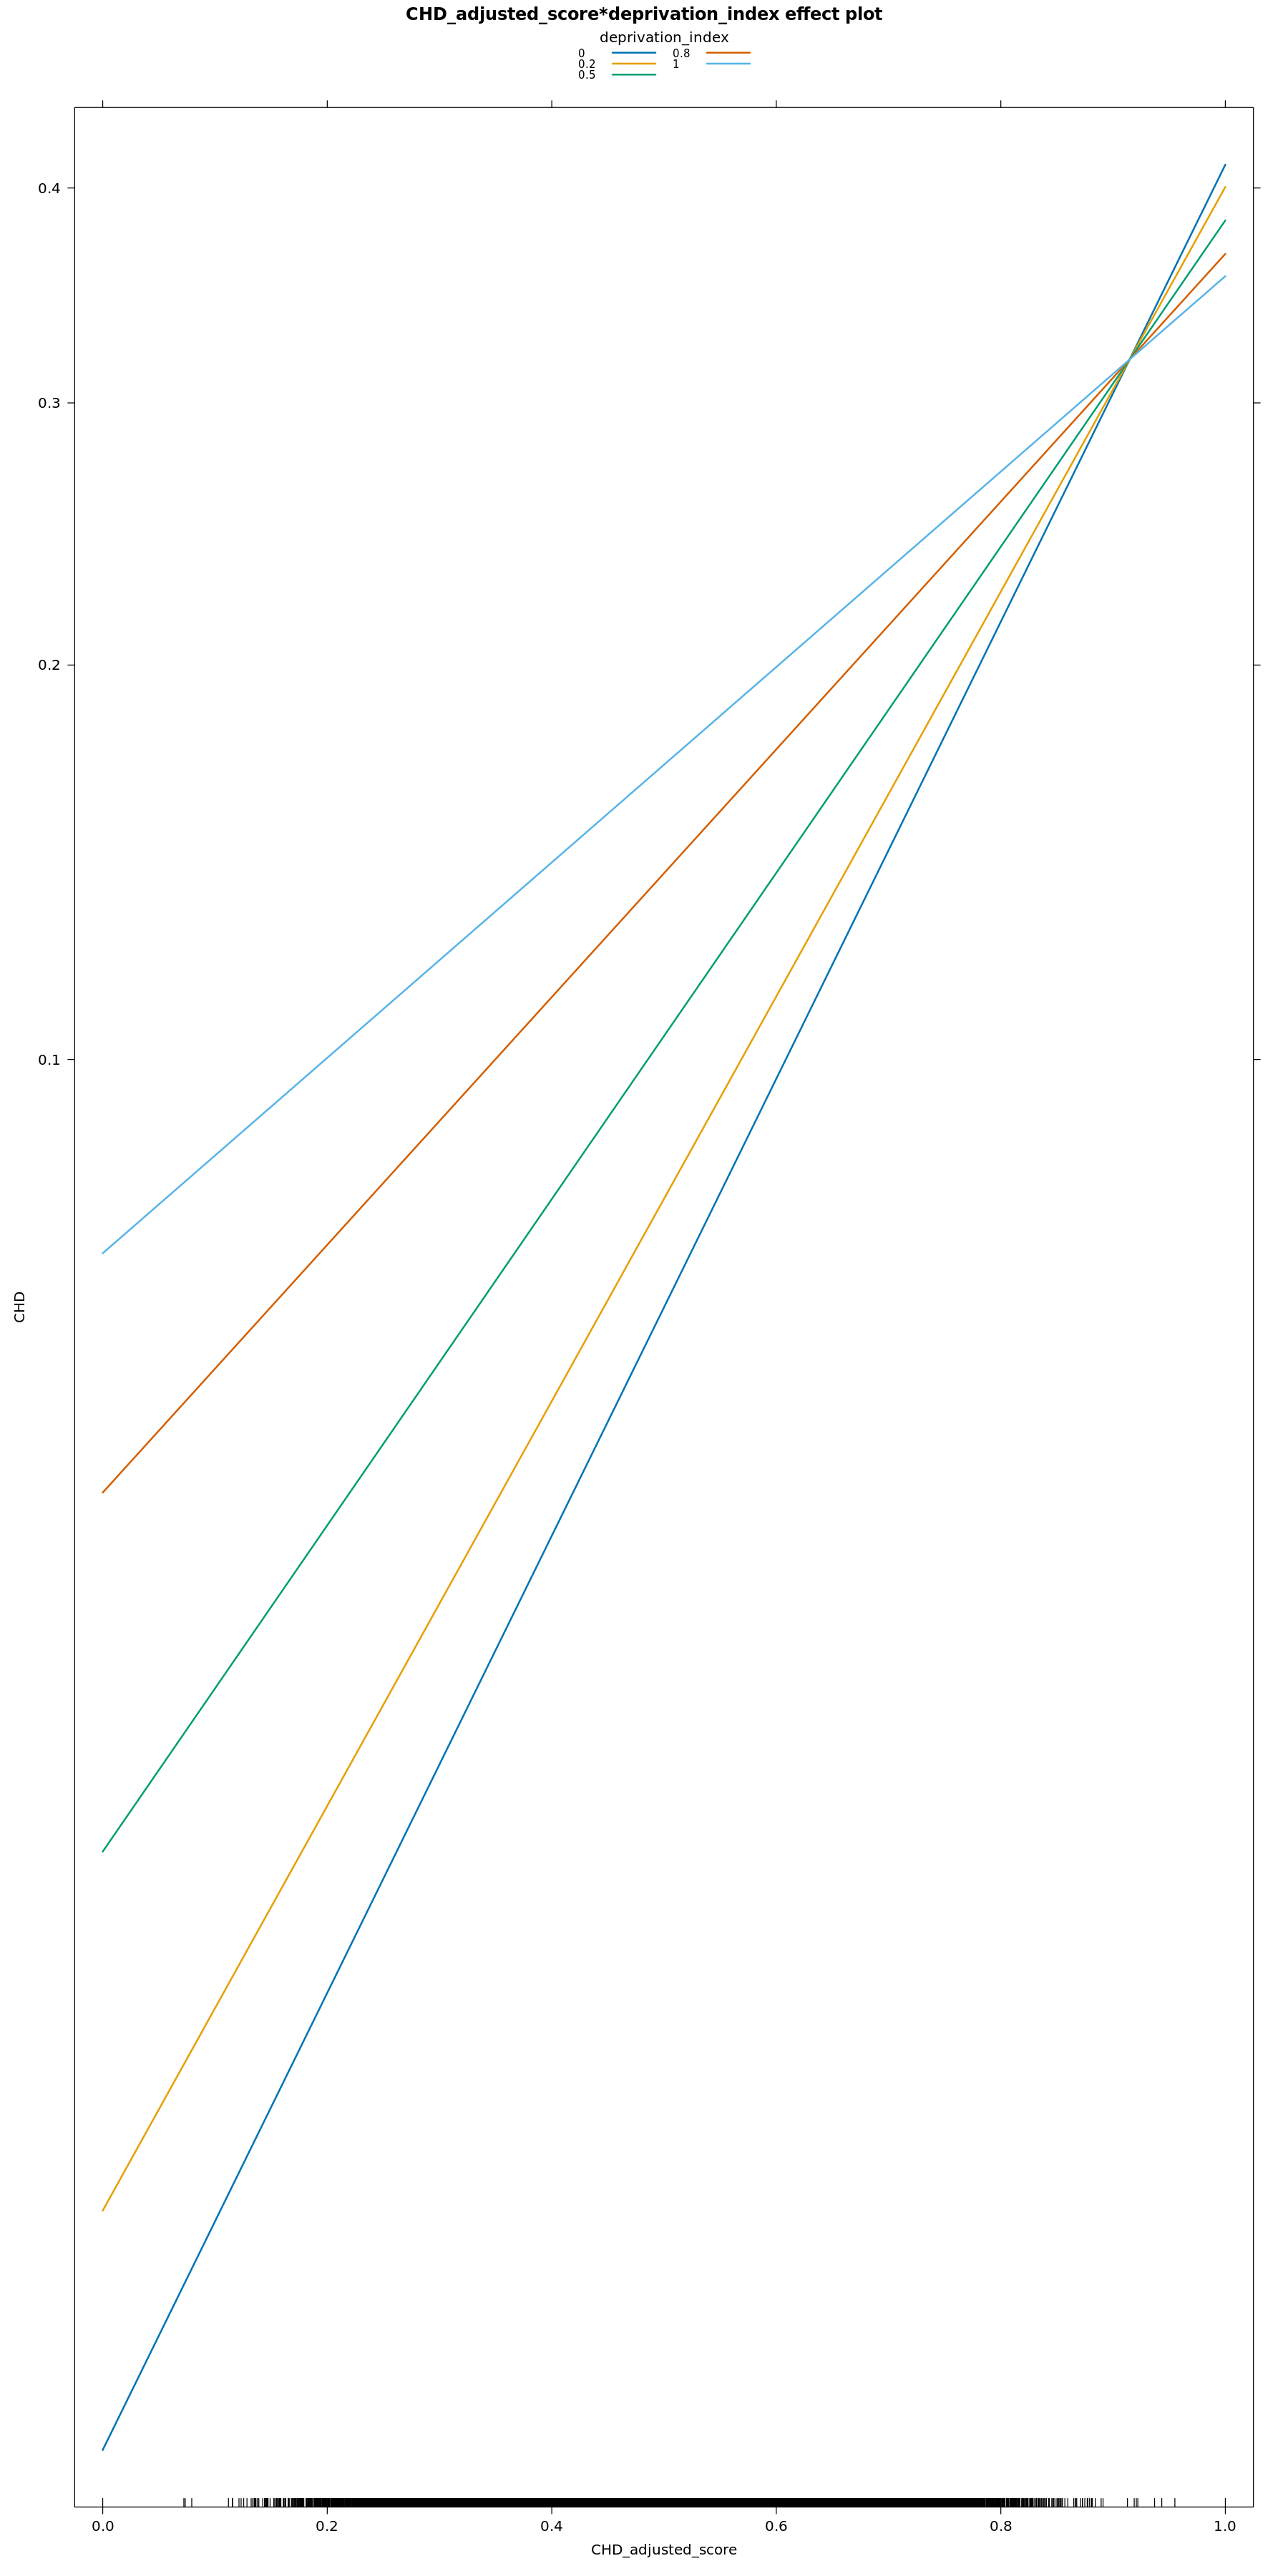

In [58]:
plot(allEffects(model)[["CHD_adjusted_score:deprivation_index"]], multiline = TRUE, title = FALSE)

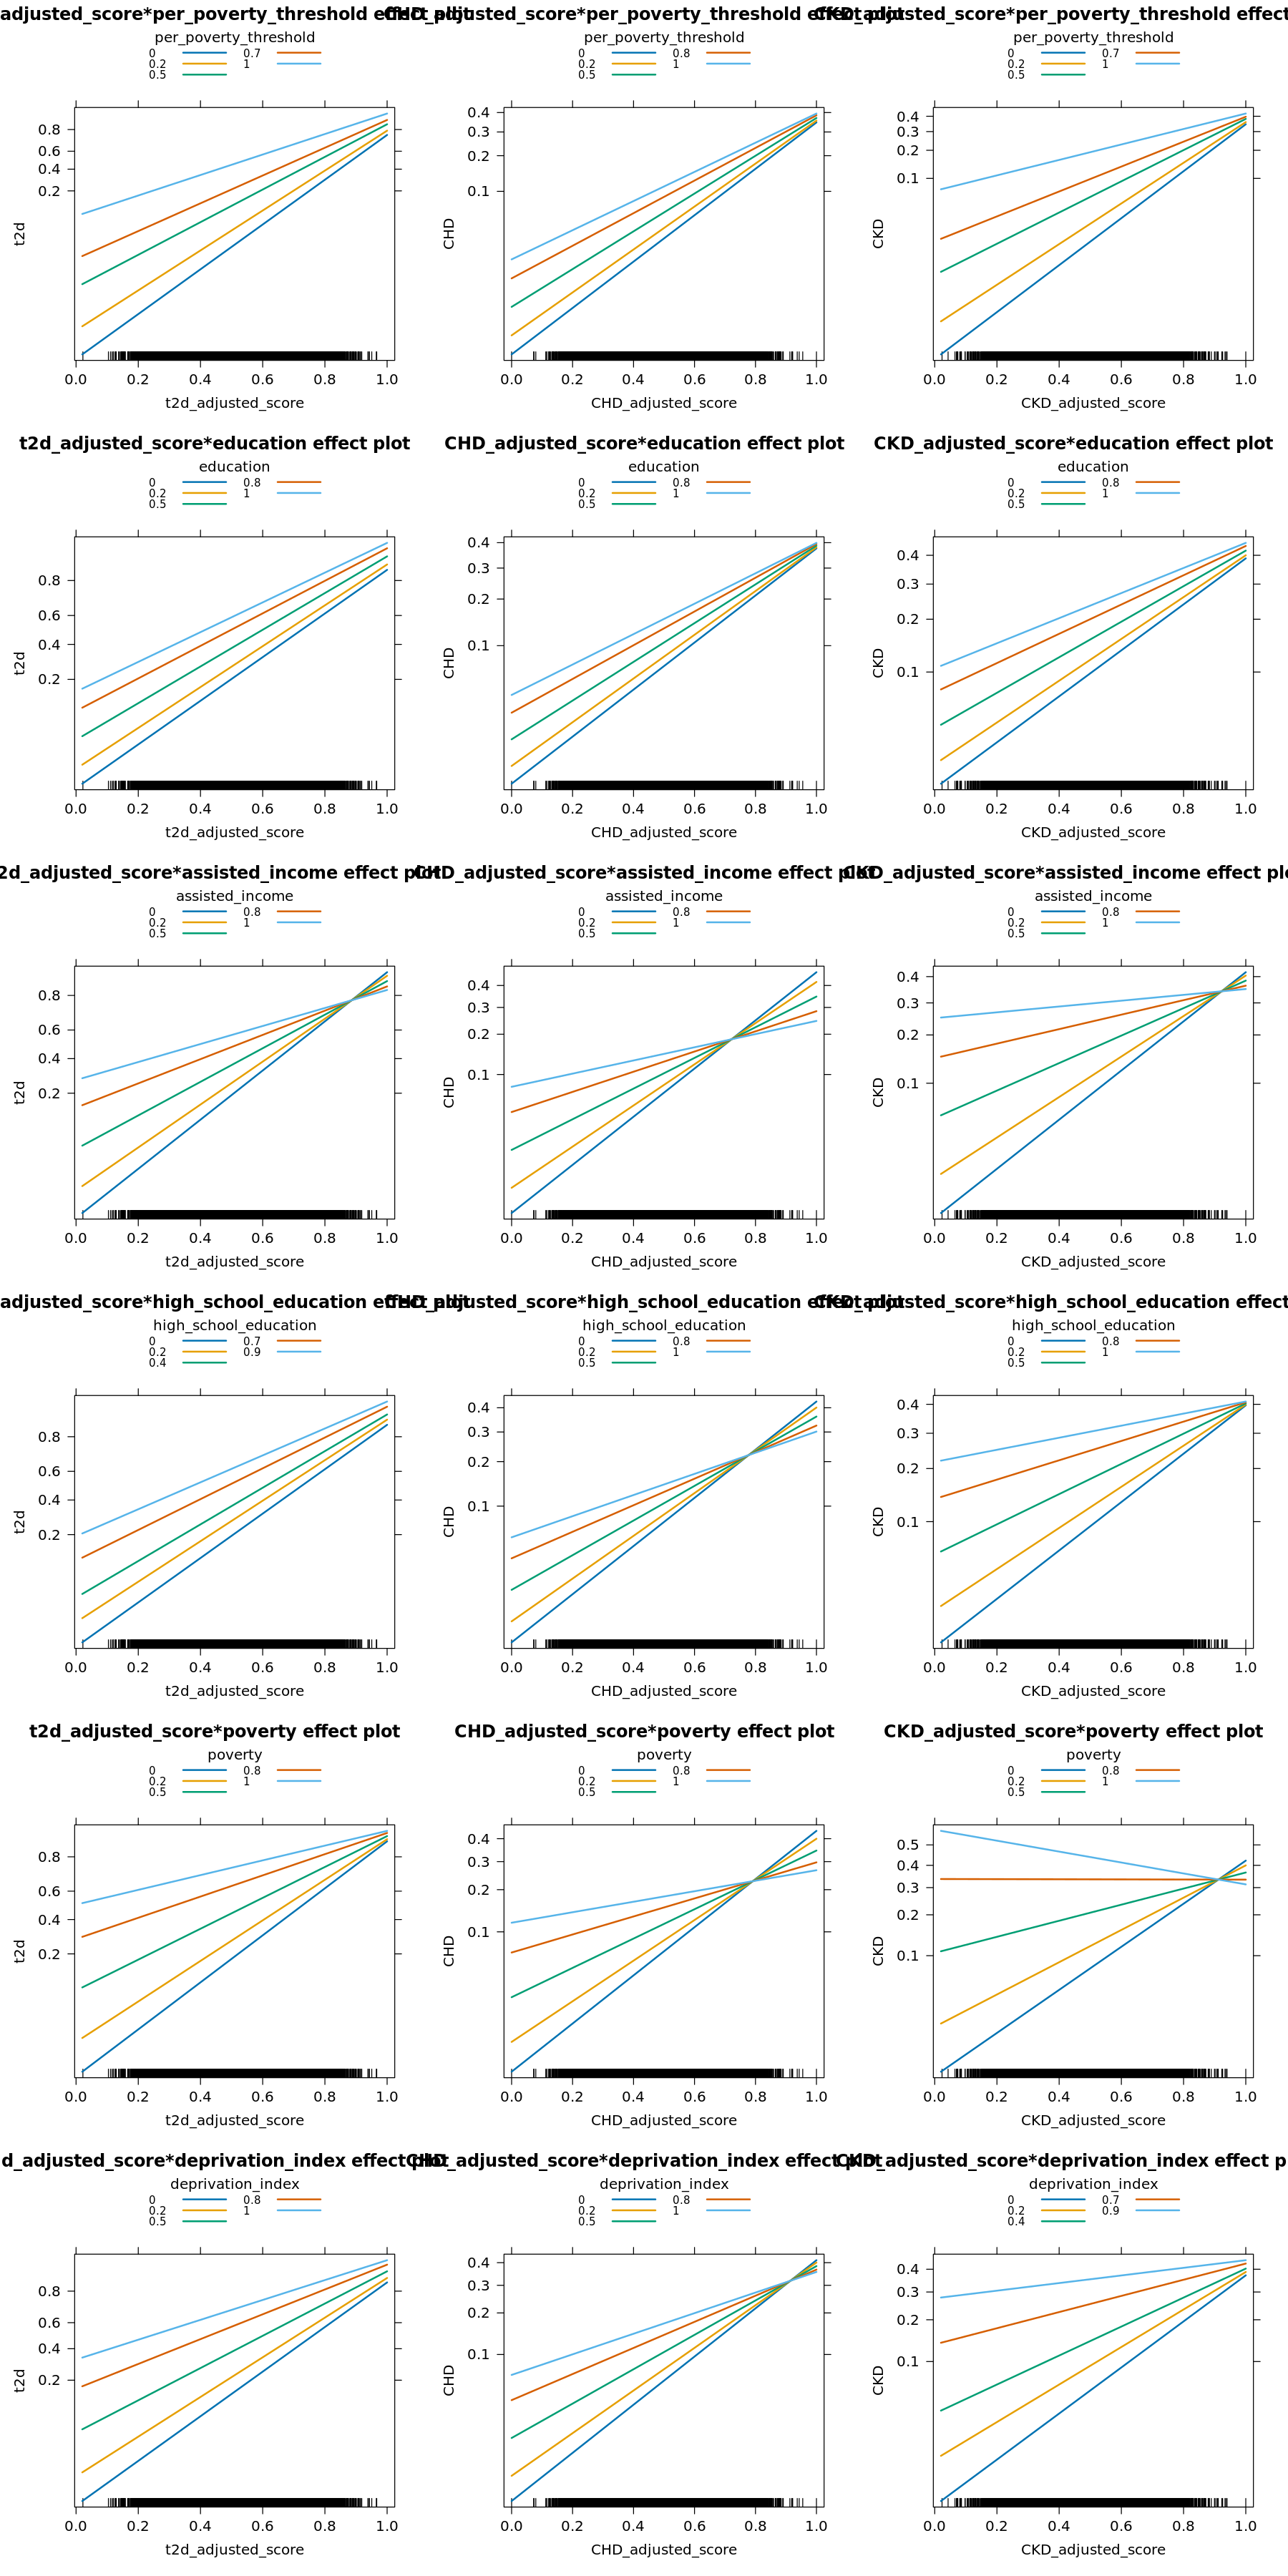

In [55]:
options(repr.plot.width = 15, repr.plot.height = 30)  # Set width and height

library(gridExtra)

grid.arrange(plot_t2d_ppt, plot_CHD_ppt, plot_CKD_ppt, 
             plot_t2d_edu,  plot_CHD_edu,  plot_CKD_edu, 
             plot_t2d_ain,  plot_CHD_ain, plot_CKD_ain, 
             plot_t2d_area_edu, plot_CHD_area_edu, plot_CKD_area_edu, 
             plot_t2d_poverty, plot_CHD_poverty, plot_CKD_poverty,
             plot_t2d_dep,  plot_CHD_dep,  plot_CKD_dep,      
             ncol = 3)

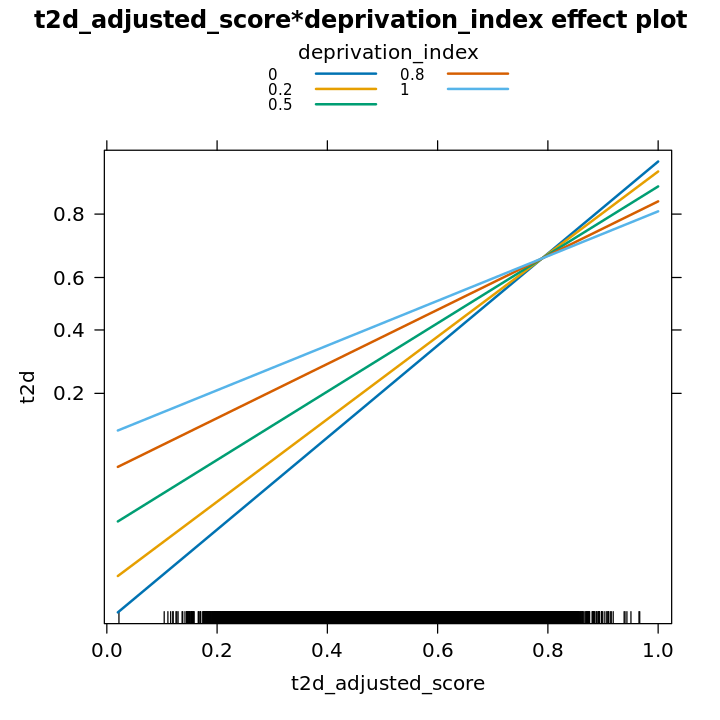

In [61]:
options(repr.plot.width = 6, repr.plot.height = 6)  # Set width and height


model<-glm(t2d ~ age + record_depth + visit_frequency + SexGenderCis_male + SexGenderSGM + 
           t2d_adjusted_score + deprivation_index + 
           t2d_adjusted_score:deprivation_index,
           data=merged_data2, family=binomial)


plot(allEffects(model)[["t2d_adjusted_score:deprivation_index"]], multiline = TRUE)

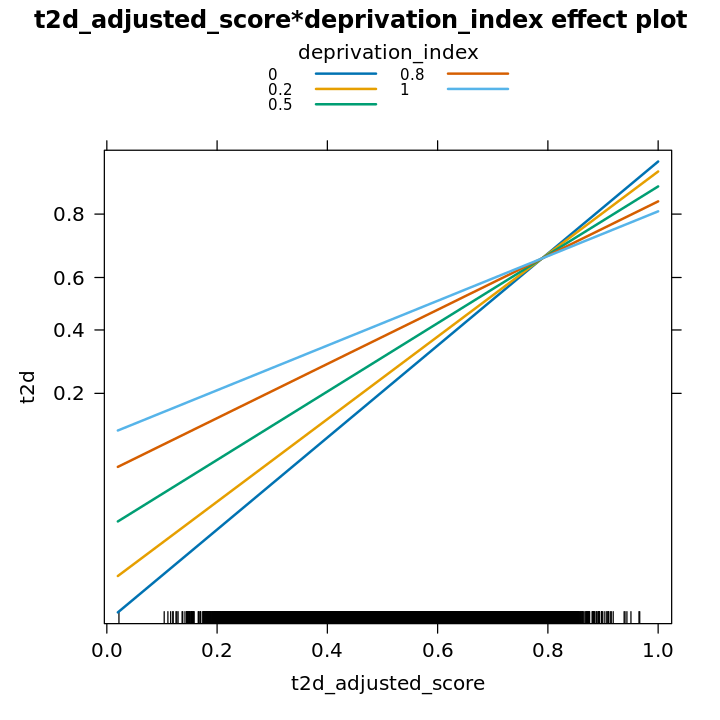

In [62]:
model<-glm(t2d ~ age + record_depth + visit_frequency + SexGenderCis_male + SexGenderSGM + 
           t2d_adjusted_score + deprivation_index + 
           PC_1 + PC_2 + PC_3 + PC_4 + PC_5 + PC_6 +
           PC_7 + PC_8 + PC_9 + PC_10 + PC_11 + PC_12 +
           PC_13 + PC_14 + PC_15 + PC_16 + 
           t2d_adjusted_score:deprivation_index,
           data=merged_data2, family=binomial)


plot(allEffects(model)[["t2d_adjusted_score:deprivation_index"]], multiline = TRUE)